# Designed hierarchy initialisations, part 2: one section per run

Continuation of `hierarchy_design_runs.ipynb` (runs 1-46 there), started on 2026-10-13 because that notebook had grown too big. **Runs
keep their global numbers** (41, then 47, 48, ... so that "run x" is unambiguous across notebooks and the session log); **sections are
numbered 1, 2, ...** Section 1 is run 41 (the 62-60-4 reduction of the anchor run 38), section 2 is run 47, and so on. The setup cell is
the first notebook's (registry, loaders, `findings_table`, `trajectory_plots`, `network_view`, `ensure_runs`), so every section runs on
its own after it.

Common ground for all runs here, unless a section says otherwise: depth-5 COB-ODT data (d = 100, tree seed 5178, 1M training points from
seed 5178, 200k test points from seed 999777); the **equivariant quadruple init** of runs 37-41 (30 probes and no spare rows, mutually
orthogonal and purely off-span; cues = pole x (v + u_j) renormalised and free; four second-layer units per node of types (block sign,
path sign) = (+,+), (+,-), (-,-), (-,+); the init is fixed by every tree flip up to a rotation of the off-span complement); SGD with
momentum 0.9, lr 0.01 -> 0.0005 cosine, batch 10k, 10 000 epochs of 100 steps, weight and momentum snapshots every 10 epochs.


In [1]:
from pathlib import Path
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
%load_ext autoreload
%autoreload 2
from layer_lenses.designed_init import HIERARCHY_TARGETS, NODE_LEVEL, hierarchy_run_summary, probe_node_outcomes, plot_probe_target_cosines, probe_deviation_lineage
from layer_lenses.relu_analysis import (snapshot_state_dict, first_layer_odt_alignment, first_layer_alignment_series,
                                         plot_first_layer_alignment_series, plot_layered_relu_graph)
from layer_lenses.init_sweep import SweepRunSpec, build_data, build_tree
from layer_lenses.relu_mlp import ReLUMLP
from layer_lenses.relu_analysis import load_designed_run


RESULTS = Path("../results/designed_init")
tree = build_tree(SweepRunSpec(tree_seed=5178, data_seed=0, init_seed=0, batch_size=1))
x_test, y_test = build_data(SweepRunSpec(tree_seed=5178, data_seed=999_777, init_seed=0, batch_size=1, n_train=100_000), tree)
X_test = torch.from_numpy(x_test).float()


def load_hier_run(folder, tag, dims):
    """Trajectory (all layers every 10 epochs), per-epoch table and summary row of one run."""
    z = np.load(RESULTS / folder / "runs" / f"{tag}.npz")
    summ = pd.read_csv(RESULTS / folder / "summary.csv")
    return {"tag": tag, "dims": dims, "epochs": z["epochs"], "losses": z["epoch_losses"], "lr": z["lr_history"],
            "W": {k[3:]: z[k] for k in z.files if k.startswith("w__")}, "per_epoch": pd.read_csv(RESULTS / folder / f"per_epoch_{tag}.csv"),
            "summary": summ[summ.tag == tag].iloc[0]}


def logits_at(run, epoch):
    m = ReLUMLP(input_dim=100, hidden_dims=run["dims"], bias=False); m.load_state_dict(snapshot_state_dict({"epochs": run["epochs"], **{f"w__{k}": v for k, v in run["W"].items()}}, epoch)); m.eval()
    with torch.no_grad():
        return m(X_test).reshape(-1).numpy()


def findings_table(run):
    """End-of-run numbers: loss, both test-error rules, zero-logit fraction, coverage and probe outcomes."""
    out = logits_at(run, int(run["epochs"][-1])); W1 = run["W"]["hidden_layers.0.weight"]
    s = hierarchy_run_summary(W1[-1], tree); L = run["losses"]; first = lambda t: int(np.nonzero(L <= t)[0][0] + 1) if (L <= t).any() else None
    rec = {"final epoch loss": round(float(L[-1]), 4), "test error (logit >= 0)": round(float(((out >= 0) != (y_test > 0)).mean()), 4), "test error (strict)": round(float(((out > 0) != (y_test > 0)).mean()), 4),
           "zero-logit fraction": round(float((out == 0).mean()), 3), "negative output weights": int((run["W"]["output_layer.weight"][-1] < 0).sum()),
           "epochs to 0.3 / 0.1 / 0.05": f"{first(0.3)} / {first(0.1)} / {first(0.05)}", "aligned rows": f"{s['aligned_rows']} / {s['rows']}", "nodes covered": f"{s['nodes_covered']} / 31, missing {s['missing_nodes']}",
           "own-probe nodes / intended / opposite": f"{s['own_probe_nodes']} / {s['intended_pole']} / {s['opposite_pole_only']}", "missed by own probes": s["missed_by_own_probes"], "both poles": s["both_poles"]}
    display(pd.Series(rec).to_frame(run["tag"]))
    return s


def trajectory_plots(run, neuron_ids, node_ids=None, start_epoch=None, end_epoch=None):
    """Loss / test error / coverage over epochs; every probe's cosine to its target; alignment series of chosen neurons.

    ``start_epoch`` / ``end_epoch`` (inclusive, in the run's own epoch units) restrict every panel to the
    snapshots and loss values inside that window; None means from the first / to the last.
    """
    ep_all = run["epochs"]; lo = ep_all[0] if start_epoch is None else start_epoch; hi = ep_all[-1] if end_epoch is None else end_epoch
    sel = (ep_all >= lo) & (ep_all <= hi)
    if not sel.any():
        raise ValueError(f"no snapshots in epochs [{lo}, {hi}]; stored epochs run {ep_all[0]}..{ep_all[-1]} every {ep_all[1] - ep_all[0]}")
    ep = ep_all[sel]; W1 = run["W"]["hidden_layers.0.weight"][sel]; W2 = run["W"]["hidden_layers.1.weight"][sel]
    loss_epochs = np.arange(1, len(run["losses"]) + 1); lsel = (loss_epochs >= max(lo, 1)) & (loss_epochs <= hi)
    cov, err = [], []
    for i, e in enumerate(ep):
        cov.append(hierarchy_run_summary(W1[i], tree)["nodes_covered"]); err.append(float(((logits_at(run, int(e)) >= 0) != (y_test > 0)).mean()))   # test error (logit >= 0 rule) at every stored checkpoint
    window = "" if start_epoch is None and end_epoch is None else f" (epochs {lo}-{hi})"
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.2))
    axes[0].plot(loss_epochs[lsel], np.asarray(run["losses"])[lsel]); axes[0].set_yscale("log"); axes[0].set_ylabel("epoch train loss")
    axes[1].plot(ep, err); axes[1].set_yscale("log"); axes[1].set_ylabel("test error (logit >= 0)")
    axes[2].plot(ep, cov); axes[2].axhline(31, color="k", ls=":", lw=0.8); axes[2].set_ylabel("nodes covered (|cos| > 0.95)")
    for ax in axes: ax.set_xlabel("epoch"); ax.grid(alpha=0.25)
    fig.suptitle(f"{run['tag']}{window}", fontsize=9); fig.tight_layout(); plt.show()
    plot_probe_target_cosines(W1, ep, tree, title=f"{run['tag']}{window}: signed cosine of each probe to its designed target"); plt.show()
    if node_ids is None:
        W_end = W1[-1]; C = (W_end / np.linalg.norm(W_end, axis=1, keepdims=True)) @ tree.w_list.T
        node_ids = sorted({HIERARCHY_TARGETS[i][0] for i in neuron_ids if i < 30} | {int(np.abs(C[i]).argmax()) for i in neuron_ids})
    series = first_layer_alignment_series(W1, ep, tree, neuron_ids=neuron_ids, node_ids=node_ids, fan_out_weights=W2)
    plot_first_layer_alignment_series(series, title=f"{run['tag']}{window}: first-layer neurons {neuron_ids} vs ODT nodes {node_ids}"); plt.show()
    return series


def network_view(run, epoch, *, align_threshold=0.5, edge_threshold=0.5, only_aligned_first_layer=False, figsize=(14, 18), mask_arg=None, even_odd_layer3=False, layer_orders=None):
    """Layered graph at one epoch (first-layer rows labelled by closest ODT node) and the row -> node table.

    even_odd_layer3=True draws the third hidden layer with all even neurons first (top) and all odd neurons after them (display only;
    labels keep the neuron indices). layer_orders={layer_index: order} gives any other top-to-bottom order per hidden layer (0-based).
    """
    if even_odd_layer3:
        n3 = run["W"]["hidden_layers.2.weight"].shape[1]; layer_orders = {**(layer_orders or {}), 2: list(range(0, n3, 2)) + list(range(1, n3, 2))}
    sd = snapshot_state_dict({"epochs": run["epochs"], **{f"w__{k}": v for k, v in run["W"].items()}}, epoch)
    mask = None
    if only_aligned_first_layer:
        al = first_layer_odt_alignment(state_dict=sd, tree=tree)
        mask = [al["max_abs_cos"].numpy() >= align_threshold] + [np.ones(sd[f"hidden_layers.{i}.weight"].shape[0], dtype=bool) for i in (1, 2)]    
    if mask_arg is not None:
        mask = mask_arg
    alignment, _, fig, ax = plot_layered_relu_graph(state_dict=sd, tree=tree, depth=5, epoch=epoch, node_mask=mask, alignment_abs_threshold=align_threshold, edge_abs_threshold=edge_threshold, figsize=figsize, layer_orders=layer_orders)
    plt.show()
    n = sd["hidden_layers.0.weight"].shape[0]
    tab = pd.DataFrame({"row": np.arange(n), "group": ["probe"] * 30 + ["cue"] * 32 + ["random"] * (n - 62), "designed_target": [HIERARCHY_TARGETS[i] if i < 30 else "" for i in range(n)],
                        "closest_node": alignment["closest_odt_np"], "level": alignment["node_level"], "signed_cos": alignment["signed_closest_cos"].numpy().round(3), "norm": alignment["row_norms"].numpy().round(2)})
    display(tab[tab.signed_cos.abs() >= align_threshold].sort_values(["level", "closest_node", "signed_cos"]).reset_index(drop=True))
    return tab

# --- run registry: how every run of this notebook is loaded, so any section can be run on its own after this cell ---
RUN_REGISTRY = {41: ("replay", "hierarchy_equivariant_60_nospare_l3x4", [62, 60, 4]),        # section 1: the 62-60-4 reduction of the anchor run 38
                47: ("replay", "hd2_run2_l3x2_kaiming", [62, 60, 2]),                        # section 2: two third-layer neurons, Kaiming rows, uniform lr
                48: ("replay", "hd2_run48_l3x2_readout", [62, 60, 2]),                       # section 3: run 47 with the readout rescaled to run 41's
                49: ("replay", "hd2_run49_l3x2_readout_10M", [62, 60, 2]),                  # section 4: run 48 with 10M points (same 1M steps)
                50: ("replay", "hd2_run50_pluscues_10M", [46, 60, 2]),                   # section 5: run 49 with the 16 +u_j cues only
                51: ("replay", "hd2_run51_phased_10M", [62, 60, 2]),                     # section 6: run 49 with phased freezing (cues 0-500, probes 500-1000, free 1000-1200)
                52: ("replay", "hd2_run52_phased2_cue05_10M", [62, 60, 2]),              # section 7: cue bias 0.5, two phases (cues frozen 0-500, free 500-1000)
                53: ("replay", "hd2_run53_phased2_cue1_10M", [62, 60, 2]),               # section 8: the bias-1 control of run 52
                54: ("replay", "hd2_run54_phased2_w2neg_10M", [62, 60, 2]),              # section 9: run 53 with W2 negated at init
                55: ("replay", "hd2_run55_phased2_2L_10M", [62, 60]),                    # section 10: run 53 without the third layer (Wout = path sign x 0.816)
                56: ("replay", "hd2_run56_phased2_2L_outx80_10M", [62, 60]),            # section 11: run 55 with the output row's gradient x80
                57: ("replay", "hd2_run57_phase1_proj_u0", [62, 60]),                    # section 12: phase 1 of run 56 with first-layer updates projected off u_0
                58: ("replay", "hd2_run58_phase1_proj_u1", [62, 60]),                   # section 13: ... projected off u_1
                59: ("replay", "hd2_run59_sgd_lr02_2000", [62, 60]),                    # section 14: run 56 with plain SGD (no momentum), lr 0.02, 2000 epochs
                60: ("replay", "hd2_run60_sgd_lr1_1000", [62, 60]),                     # section 15: plain SGD at lr 0.1 over 1000 epochs (run 56's effective step)
                61: ("replay", "hd2_run61_phase1_randcue_n1", [62, 60]),                # section 16: phase 1 of run 60 with node 1's units reading a random cue vector v, v, -v, -v
                62: ("replay", "hd2_run62_cuenoise_r1", [62, 60]),                      # section 17: run 60 with every cue block v_j + n_j, n_j random in the complement of span{v_j}, |n_j| = |v_j|
                63: ("replay", "hd2_run63_gradcue", [62, 60]),                          # section 18: run 60 with the cue blocks replaced by the single-unit gradient direction at the ideal W1 (c = -1, 1/100 cues)
                67: ("replay", "hd2_run67_symcue_pilot", [62, 60]),                     # section 22: pilot, majority-label cue blocks 0.2 / 0.1, readouts 0.01, phase 1 for 20 epochs (runs 64-66, sections 19-21, were killed by a restart and superseded)
                68: ("replay", "hd2_run68_symcue_outx1", [62, 60]),                    # section 23: majority-label cue blocks, readouts +-0.816, output rate x1
                69: ("replay", "hd2_run69_symcue_flipped", [62, 60])}                   # section 24: run 68 with the doubling flipped (0.1 on the open side, 0.2 elsewhere)

def load_replay_run(folder, dims):
    """(seed_result, run dict) of a replayable run written by save_designed_run: trajectories of all layers every 10 epochs, losses, lr, tables."""
    sr = load_designed_run(RESULTS / folder / "replay"); _out = sr["out"]; _ep = np.array(sorted(_out["checkpoint_snapshots"]))
    run = {"tag": sr["tag"], "dims": dims, "epochs": _ep, "losses": np.array(_out["epoch_losses"]), "lr": np.array(_out["lr_history"]),
           "W": {key: np.stack([_out["checkpoint_snapshots"][e][key].numpy() for e in _ep]) for key in _out["checkpoint_snapshots"][_ep[0]]},
           "per_epoch": pd.read_csv(RESULTS / folder / f"per_epoch_{sr['tag']}.csv"), "summary": pd.read_csv(RESULTS / folder / "summary.csv").iloc[0]}
    return sr, run


def ensure_runs(*numbers):
    """Load every listed run that is not in the notebook namespace yet (as run<n>, plus sr<n> for replayable runs); returns {n: run<n>}.

    Cross-run cells at the end of a section call this, so a section can be run on its own after a kernel restart and this cell.
    """
    g = globals(); loaded = {}
    for n in numbers:
        if f"run{n}" not in g:
            kind, *spec = RUN_REGISTRY[n]
            if kind == "hier":
                g[f"run{n}"] = load_hier_run(*spec)
            else:
                g[f"sr{n}"], g[f"run{n}"] = load_replay_run(*spec)
            print(f"ensure_runs: loaded run {n} ({spec[0]})")
        loaded[n] = g[f"run{n}"]
    return loaded


## 1. Run 41: the 62-60-4 reduction of the anchor run 38

| setting | value |
|---|---|
| init | run 38's (62-60-40 equivariant quadruples) with the third layer replaced by its four distinct neurons (S, +) x15, (S, -) x5, (Sc, +) x5, (Sc, -) x15, S reading the path-sign-+ units; the multiplicity m is folded into the output weight (m x 0.2236) and into gradient scales (m on the output weight, 1/m on the W3 row) |
| protocol | SGD momentum 0.9, lr 0.01 -> 0.0005 cosine, 1M points, batch 10k, 10 000 epochs |
| storage | `results/designed_init/hierarchy_equivariant_60_nospare_l3x4/replay/` |
| script | `run_hierarchy_equivariant60.py --no-spare --reduced-l3` |

**Findings** (from the first notebook, section 41). Loss 0.0033, test error 0.49%, all 31 nodes, 29 of 30 probes on their own node, no spikes; identical to run 38 until float-32 chaos separates them (weights within 3e-5 at epoch 10, 1% at epoch 300). The output weights end at 80.1 / 18.1 / -19.7 / -84.7: the two 5-copy classes flip their output sign and end as weaker versions of the 15-copy classes, which motivates run 2.


In [ ]:
sr41, run41 = load_replay_run("hierarchy_equivariant_60_nospare_l3x4", [62, 60, 4])          # ~20 s
summary41 = findings_table(run41)

In [ ]:
NEURON_IDS = [0, 1, 2, 3]
series41 = trajectory_plots(run41, NEURON_IDS, node_ids=None, end_epoch=10000)

In [ ]:
GRAPH_EPOCH = 0
table41 = network_view(run41, GRAPH_EPOCH, align_threshold=0.8, edge_threshold=0.05)

## 2. Run 47: two third-layer neurons, Kaiming scale in every layer, uniform learning rate (62-60-2)

| setting | value |
|---|---|
| init | run 41's with the two redundant third-layer neurons (the 5-copy classes, which flip sign) removed: W3 = [S; Sc] with 30 entries of sqrt(2/30) = 0.258 per row, output (+1, -1); every layer's rows have norm sqrt(2) (W1 and W2 already did). The effective output weight per unit is +-0.258 (run 41: +-0.816). No gradient scales, nothing frozen |
| protocol | SGD momentum 0.9, lr 0.01 -> 0.0005 cosine, 1M points, batch 10k, 10 000 epochs |
| storage | `results/designed_init/hd2_run2_l3x2_kaiming/replay/` |
| script | `run_hd2_l3x2.py --out hd2_run2_l3x2_kaiming --tag hd2_run2_l3x2_kaiming_seed0` (the folder keeps its pre-renumbering name) |

**Findings.**
- Loss 0.0102, test error 0.71%, 29 of 31 nodes, no spikes, 28 min; run 41: 0.0033 / 0.49% / 31. Slower throughout: loss 0.1 at epoch 1039 (run 41: 418), 0.05 at 2611 (716), never below 0.01 (5326).
- Fates: 19 of 30 probes on their own node (run 41: 28); 8 deviations, all level-3 probes going to a child level-4 node (-u_7 -> u_16, +u_8 -> -u_17, ..., +u_14 -> -u_29), 0 unrelated, and three level-3 probes short of capture; the cues end 10 on their own normal and 13 on ancestors (run 41: 23 / 7). The lineage rule holds; the level-3 / level-4 competition is lost more often.
- Two third-layer neurons are enough: the output ends at (+21.3, -21.2) and W3 entries reach 5.5, a readout as large as run 41's (|w_eff| 76 vs 110). What the run lacks is the *initial* readout scale: the Kaiming rows give an effective output weight of +-0.258 per unit against run 41's +-0.816, and since the factorised readout grows at a rate set by its own size, the early phase is six times slower (|w_eff| 5.4 vs 33 at epoch 100, 49 vs 86 at epoch 1000). The first layer catches up only partly (level-3 own-coordinate spread 0.07 / 1.55 / 4.1 at epochs 200 / 1000 / 10000 vs 0.49 / 3.4 / 5.2).
- So the reduction to two neurons costs nothing in principle, and the gap to run 41 is a readout-scale effect: a run 3 with the same two-neuron Kaiming design but the readout scaled to +-0.816 (output +-sqrt(10), or W3 rows at norm 2 sqrt 2) would separate the two (run 48).


In [ ]:
sr47, run47 = load_replay_run("hd2_run2_l3x2_kaiming", [62, 60, 2])          # ~20 s
summary47 = findings_table(run47)

In [ ]:
NEURON_IDS = [0, 1, 2, 3]
series47 = trajectory_plots(run47, NEURON_IDS, node_ids=None, end_epoch=10000)

In [ ]:
GRAPH_EPOCH = 1000
table47 = network_view(run47, GRAPH_EPOCH, align_threshold=0.8, edge_threshold=0.05)

In [ ]:
# Cross-run cell: uses runs 41 and 47 (loads run 41 if needed). Loss, fates, the two output weights and the effective output scale against run 1.
ensure_runs(41)
from layer_lenses.designed_init import probe_deviation_lineage
_rows = []
for n in [41, 47]:
    r = globals()[f"run{n}"]; W = r["W"]; lin = probe_deviation_lineage(W["hidden_layers.0.weight"][-1], tree); s = r["summary"]; L = r["losses"]; d = np.abs(np.diff(np.log(L)))
    w_eff = W["output_layer.weight"][:, 0, :] @ W["hidden_layers.2.weight"]
    _rows.append({"run": n, "dims": r["dims"], "final loss": round(float(s.final_epoch_loss), 4), "test error": round(float(s.test_error_end), 4), "nodes": int(s.nodes_covered_end), "probes own node": int((~lin.deviated & (lin.end_cos.abs() >= 0.95)).sum()),
                  "spiky epochs": int((d > 0.3).sum()), "epoch to 0.1 / 0.05 / 0.01": f"{int(s['epoch_to_0.1'])} / {int(s['epoch_to_0.05'])} / {int(np.argmax(L <= 0.01)) + 1 if (L <= 0.01).any() else -1}",
                  "w_out end": np.round(W["output_layer.weight"][-1][0], 2).tolist(), "|w_eff| ep 100 / 1000 / end": " / ".join(f"{np.abs(w_eff[int(np.searchsorted(r['epochs'], e))]).mean():.1f}" for e in (100, 1000, int(r["epochs"][-1])))})
print(pd.DataFrame(_rows).to_string(index=False))
plt.figure(figsize=(8, 3)); [plt.plot(globals()[f"run{n}"]["losses"], lw=0.7, label=f"run {n}") for n in [41, 47]]; plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("epoch loss"); plt.legend(); plt.show()

## 3. Run 48: run 47 with the readout rescaled to run 41's

| setting | value |
|---|---|
| init | run 47's (62-60-2, uniform lr) with the readout rescaled: W3 entries e = 1.633 (rows S, Sc at norm 8.9), output w = +-0.5, so the effective output weight per unit is e w = +-0.816 as in run 41 **and** the factorised readout's shared-mode rate at init, lr x (30 e^2 + 2 w^2) = 80.5 lr, matches run 41's full model (30 x 2.67 + 2 = 82); run 47 had 4, and either single-layer rescaling to +-0.816 (e = 0.816, w = 1 or e = 0.258, w = 3.16) would give 22. Logit rms at init 0.049 (run 41: 0.049, run 47: 0.016) |
| protocol | run 47's: SGD momentum 0.9, lr 0.01 -> 0.0005 cosine, 1M points, batch 10k, 10 000 epochs |
| storage | `results/designed_init/hd2_run48_l3x2_readout/replay/` |
| script | `run_hd2_l3x2.py --w3-entry 1.633 --out-weight 0.5` |

**Findings.**
- Loss 0.0029, test error 0.46%, all 31 nodes, no spikes, 27 of 30 probes on their own node (3 level-3 probes to a child: +u_10 -> u_21, +u_13 -> -u_27, +u_14 -> -u_29), cues 21 own / 6 on ancestors. This is run 41 (0.0033 / 0.49%, 31 nodes, 28 probes) reproduced by a 62-60-2 network with a uniform learning rate.
- Not only the end state: the trajectory statistics coincide with run 41's. Loss 0.1 at step 41 400 (run 41: 41 800), 0.05 at 71 800 (71 600); |w_eff| 33.8 / 86.0 / 110.6 at 10k / 100k / 1M steps (33.4 / 85.9 / 110.3); level-3 own-coordinate spread 0.50 / 3.38 / 5.28 (0.49 / 3.37 / 5.23). The two neurons end at (+22.2, -23.6).
- So the four-neuron layer, its multiplicities and the gradient scales were all stand-ins for two numbers: the effective output weight per unit (+-0.816) and the readout's shared-mode rate at init (30 e^2 + 2 w^2 = 80.5 vs 82). With those matched, run 47's gap (0.0102, 19 probes) closes completely. The anchor's dynamics live in a 62-60-2 model with one learning rate.


In [ ]:
sr48, run48 = load_replay_run("hd2_run48_l3x2_readout", [62, 60, 2])          # ~20 s
summary48 = findings_table(run48)

In [ ]:
NEURON_IDS = [0, 1, 2, 3]
series48 = trajectory_plots(run48, NEURON_IDS, node_ids=None, end_epoch=int(run48["epochs"][-1]))

In [ ]:
GRAPH_EPOCH = 0
table48 = network_view(run48, GRAPH_EPOCH, align_threshold=0.8, edge_threshold=0.05)

## 4. Run 49: run 48 with ten times the data (10M points, same 1M steps)

| setting | value |
|---|---|
| init | run 48's |
| protocol | 10M training points (seed 5178, chunked), batch 10k, 1000 epochs of 1000 steps: the same 1M steps and the same cosine schedule in step units as run 48; each point is seen 100 times instead of 1000; snapshots every epoch (1000 steps, as before) |
| storage | `results/designed_init/hd2_run49_l3x2_readout_10M/replay/` |
| script | `run_hd2_l3x2.py --w3-entry 1.633 --out-weight 0.5 --n-train 10000000 --epochs 1000 --snap 1` |

**Findings.**
- With ten times the data and the same 1M steps: test error 0.17% (run 48: 0.46%), all 31 nodes, **all 30 probes on their own node, no deviations**, no spikes; the final epoch-mean training loss is 0.0055 (run 48: 0.0029, which is the 1M-point sample being fitted: its test error is 2.7x worse). The cues end 21 on their own normal and 11 on ancestors.
- Faster, not slower: loss 0.1 at step 39 000 (run 48: 41 400), 0.05 at 55 000 (71 800), 0.01 at 520 000 (393 000, but on a loss that keeps falling with the sample). |w_eff| 32 / 85 / 102 at 10k / 100k / 1M steps, run 48's growth.
- **The level-3 symmetry breaking almost disappears.** The within-class spread of the level-3 probes' own coordinate is 0.14 / 0.25 / 0.34 at 20k / 100k / 1M steps against 0.50 / 3.38 / 5.28 in run 48, and the level-3 residual (in-span components that must vanish on the symmetric subspace) ends at 0.005 vs 0.019; the level-3 probes stay congruent to the end and every one of them captures its node. With the sample's asymmetry reduced by sqrt(10), the fringe fates that varied from run to run are gone, which identifies them as sample-induced and the infinite-data solution as the fully symmetric one: every probe on its node, the symmetric subspace never left.


In [ ]:
sr49, run49 = load_replay_run("hd2_run49_l3x2_readout_10M", [62, 60, 2])          # ~20 s
summary49 = findings_table(run49)

In [ ]:
NEURON_IDS = [0, 1, 2, 3]
series49 = trajectory_plots(run49, NEURON_IDS, node_ids=None, end_epoch=int(run49["epochs"][-1]))

In [ ]:
GRAPH_EPOCH = 1000
table49 = network_view(run49, GRAPH_EPOCH, align_threshold=0.8, edge_threshold=0.05)

In [ ]:
# Cross-run cell: uses runs 41, 47, 48 and 49 (loads the missing ones). Readout scale and data size: loss, fates, output growth, congruence. x axis in steps for run 49.
ensure_runs(41, 47, 48)
from layer_lenses.designed_init import probe_deviation_lineage, cue_row_identity, node_ancestors, symmetric_coordinates, symmetric_class_summary
_rows = []
for n in [41, 47, 48, 49]:
    r = globals()[f"run{n}"]; W = r["W"]; sr = globals()[f"sr{n}"]; steps_per_epoch = int(sr["data_spec"]["n_train"]) // 10_000; lin = probe_deviation_lineage(W["hidden_layers.0.weight"][-1], tree); s = r["summary"]; L = r["losses"]; d = np.abs(np.diff(np.log(L)))
    w_eff = W["output_layer.weight"][:, 0, :] @ W["hidden_layers.2.weight"]; cr = sr["design"]["cue_rows"]; cid = cue_row_identity(W["hidden_layers.0.weight"][0].astype(np.float64), tree, cr); inv = {v: k for k, v in cid.items()}
    C = W["hidden_layers.0.weight"][-1] / np.linalg.norm(W["hidden_layers.0.weight"][-1], axis=1, keepdims=True) @ tree.w_list.T
    summ = symmetric_class_summary(symmetric_coordinates(W["hidden_layers.0.weight"][-1].astype(np.float64), tree, cue_rows=cr, cue_identity=cid)).set_index("cls")
    _rows.append({"run": n, "points": sr["data_spec"]["n_train"], "final loss": round(float(s.final_epoch_loss), 4), "test error": round(float(s.test_error_end), 4), "nodes": int(s.nodes_covered_end), "probes own": int((~lin.deviated & (lin.end_cos.abs() >= 0.95)).sum()), "unrelated": int((lin.relation == "unrelated").sum()),
                  "cues own / anc": f"{sum(1 for rr in cr if abs(C[rr]).argmax() == inv[rr][0] and abs(C[rr]).max() > 0.95)} / {sum(1 for rr in cr if abs(C[rr]).max() > 0.95 and abs(C[rr]).argmax() in node_ancestors(inv[rr][0]))}", "spiky": int((d > 0.3).sum()),
                  "step to loss 0.1 / 0.05": f"{int(s['epoch_to_0.1']) * steps_per_epoch} / {int(s['epoch_to_0.05']) * steps_per_epoch}", "|w_eff| at 10k / 100k steps / end": " / ".join(f"{np.abs(w_eff[int(np.searchsorted(r['epochs'] * steps_per_epoch, st))]).mean():.1f}" for st in (10_000, 100_000, 1_000_000)),
                  "L3 own spread end": round(float(summ.loc["probe_L3", "own_spread"]), 2)})
print(pd.DataFrame(_rows).to_string(index=False))
plt.figure(figsize=(9, 3.5))
for n in [41, 47, 48, 49]:
    r = globals()[f"run{n}"]; spe = int(globals()[f"sr{n}"]["data_spec"]["n_train"]) // 10_000; plt.plot(np.arange(1, len(r["losses"]) + 1) * spe, r["losses"], lw=0.7, label=f"run {n}")
plt.xscale("log"); plt.yscale("log"); plt.xlabel("step"); plt.ylabel("epoch-mean loss"); plt.legend(); plt.show()

## 5. Run 50: run 49 with only the 16 cues on +u_j (46-60-2)

| setting | value |
|---|---|
| init | run 49's with the 16 minus-pole cue rows (-u_j) removed: 30 probes + 16 cues on +(v + u_j). Each unit's cue block keeps its coefficients on the remaining cues (-side x c), so it is no longer the linear feature c x (sum of a_m on the left - sum on the right) but a sum of relu(v + u_m) terms; the W2 rows are rescaled back to norm sqrt(2) (they had dropped to 1.22). Readout e = 1.633, w = +-0.5 as in runs 48-49. The tree flips still fix the init (worst deviation 2e-15: flips never negate a level-4 normal); the label-negation symmetry, which paired each cue with its twin, is gone. Logit rms at init 0.039 (run 49: 0.049) |
| protocol | run 49's: 10M points, batch 10k, 1000 epochs of 1000 steps, SGD momentum 0.9, lr 0.01 -> 0.0005 cosine, snapshots every epoch |
| storage | `results/designed_init/hd2_run50_pluscues_10M/replay/` |
| script | `run_hd2_l3x2.py --w3-entry 1.633 --out-weight 0.5 --plus-cues-only --n-train 10000000 --epochs 1000 --snap 1` |
| question | the +-u_j cue pairs may be redundant (a level-4 node needs only one of its two poles captured for a good loss), which would explain why some cues, despite starting at cosine 0.46 with their normal, never capture it. With one cue per level-4 node, do all 16 capture their own normal? |

**Findings.**
- Loss 0.0222, test error 0.59%, 27 of 31 nodes (14 of 16 level-4 nodes), no spikes; run 49: 0.0055 / 0.17% / 31 / 16. Four times slower: loss 0.1 at step 144 000 (run 49: 39 000), 0.05 at 504 000 (55 000), never 0.01.
- **Cues: 10 of 16 on their own normal, 1 on an ancestor, 5 stuck between (|cos| 0.6-0.7 with a normal, cue 22's probe-like row nearest to u_1).** With two cues per node (run 49) 21 of 32 ended on their own normal and 11 climbed to an ancestor, and every level-4 node kept at least one cue: the pairs were redundant for coverage, and the surplus cue of 11 pairs was reassigned to an internal node. With one cue per node nothing can leave without uncovering a level-4 node, so only one climbs, five stall, and two level-4 nodes end uncovered. Capture is also slower (0 of 16 on their normal at epoch 30 vs 16 of 32, 8 of 16 at epoch 50).
- **Probes: 20 of 30 on their own node** (run 49: 30 of 30): four level-3 probes go to a child (-u_9 -> u_20, +u_10 -> u_22, -u_11 -> u_24, +u_12 -> u_25) and six stay short of capture; probe capture is slower too (6 of 30 at epoch 30 vs 14). The level-3 symmetry breaking is back despite the 10M points: level-3 own-coordinate spread 6.4 (run 49: 0.34).
- Reading: the +-cue pairs are redundant for level-4 coverage, as suspected, but that redundancy is what the design uses: the surplus cues become the internal-node rows the probes fail to supply, and the paired block gives each unit an exactly linear level-4 feature; with the twins gone the blocks are half-rectified, the probes capture later, the level-3 competition is lost to the sample's fluctuations again, and the loss is 4x worse. The label-negation symmetry is gone as well: the output ends at (+25.8, -10.9) against run 49's (+24.4, -18.9).


In [ ]:
sr50, run50 = load_replay_run("hd2_run50_pluscues_10M", [46, 60, 2])          # ~20 s
summary50 = findings_table(run50)

In [ ]:
NEURON_IDS = [0, 1, 2, 3]
series50 = trajectory_plots(run50, NEURON_IDS, node_ids=None, end_epoch=int(run50["epochs"][-1]))

In [ ]:
GRAPH_EPOCH = 1000
table50 = network_view(run50, GRAPH_EPOCH, align_threshold=0.8, edge_threshold=0.05)

In [ ]:
# Cross-run cell: uses runs 49 and 50 (loads run 49 if needed). Cue fates with 32 vs 16 cues: own normal, ancestor, other, diffuse; probe fates; loss.
ensure_runs(49)
from layer_lenses.designed_init import probe_deviation_lineage, cue_row_identity, node_ancestors
_rows = []
for n in [49, 50]:
    r = globals()[f"run{n}"]; W = r["W"]["hidden_layers.0.weight"]; cr = globals()[f"sr{n}"]["design"]["cue_rows"]; cid = cue_row_identity(W[0].astype(np.float64), tree, cr); inv = {v: k for k, v in cid.items()}
    C = W[-1] / np.linalg.norm(W[-1], axis=1, keepdims=True) @ tree.w_list.T; lin = probe_deviation_lineage(W[-1], tree); s = r["summary"]
    kinds = {"own": 0, "ancestor": 0, "other level-4": 0, "diffuse": 0}; where = []
    for rr in cr:
        top = int(abs(C[rr]).argmax()); c = float(C[rr][top]); m, q = inv[rr]
        if abs(c) <= 0.95: kinds["diffuse"] += 1
        elif top == m: kinds["own"] += 1
        elif top in node_ancestors(m): kinds["ancestor"] += 1; where.append((m, q, top, round(c, 2)))
        else: kinds["other level-4"] += 1; where.append((m, q, top, round(c, 2)))
    _rows.append({"run": n, "cues": len(cr), "final loss": round(float(s.final_epoch_loss), 4), "test error": round(float(s.test_error_end), 4), "nodes": int(s.nodes_covered_end), "level-4 nodes covered": len(set(k for k in np.abs(C).argmax(1)[np.abs(C).max(1) > 0.95] if k >= 15)),
                  "probes own": int((~lin.deviated & (lin.end_cos.abs() >= 0.95)).sum()), **{f"cues {k}": v for k, v in kinds.items()}, "cues elsewhere (node, pole, end, cos)": where})
print(pd.DataFrame(_rows).T.to_string())
plt.figure(figsize=(8, 3)); [plt.plot(np.arange(1, len(globals()[f"run{n}"]["losses"]) + 1) * 1000, globals()[f"run{n}"]["losses"], lw=0.7, label=f"run {n}") for n in [49, 50]]; plt.xscale("log"); plt.yscale("log"); plt.xlabel("step"); plt.ylabel("epoch-mean loss"); plt.legend(); plt.show()

## 6. Run 51: run 49 with a phased protocol (cues frozen, then probes frozen, then everything free)

| setting | value |
|---|---|
| init | run 49's (62-60-2, orthogonal off-span probes, cues pole x (v + u_j), readout e = 1.633 / w = 0.5; anchor run as of 2026-10-14) |
| protocol | 10M points, batch 10k, 1000 steps per epoch, SGD momentum 0.9, one cosine schedule lr 0.01 -> 0.0005 over the 1200 epochs; **epochs 0-500: the 32 cue rows frozen** (probes, W2, W3, output train); **epochs 500-1000: the 30 probe rows frozen** (cues and the rest train); **epochs 1000-1200: nothing frozen**. Three chained segments (`stop_epoch`, `start_epoch`, the previous segment's optimizer state), momentum buffers and schedule continuous across the phase changes, snapshots every epoch, saved as one replayable run |
| storage | `results/designed_init/hd2_run51_phased_10M/replay/` |
| script | `run_hd2_phased.py --out hd2_run51_phased_10M --tag hd2_run51_phased_10M_seed0` (`--phases 500 500 200`) |

**Findings.**
- **The designed solution, exactly: all 30 probes on their own node, all 32 cues on their own normal, 0 on ancestors, all 31 nodes covered**, test error 0.12% (run 49: 0.17%, the best so far), final loss 0.0050 (0.0055), no spikes. The level-3 within-class spread ends at 0.08 (run 49: 0.34): the most symmetric end state of the series.
- Phase 1 (cues frozen, epochs 0-500): the probes capture all 30 nodes by epoch 40, earlier than in run 49 (10 captured at epoch 20 vs 2), but the loss plateaus at 0.07-0.11 with only 15 nodes covered, since the frozen cues sit at cosine 0.46 with their normals and nothing holds the level-4 nodes. The readout still grows to 100.
- Phase 2 (probes frozen, 500-1000): every cue goes to its own normal (own coordinate 0.65 -> 1.78 by epoch 700 -> 2.30), none climbs: with the probes already on the internal nodes there is no vacancy for a surplus cue to fill. Loss 0.011 at epoch 1000.
- Phase 3 (all free, 1000-1200, lr 0.0012 -> 0.0005): loss 0.011 -> 0.0050, nothing moves off its node.
- Reading: the 11 cues that climbed to ancestors in run 49 were a competition artefact of simultaneous training (cues reaching internal nodes while the probes were still travelling), not a feature the solution needs; ordering the two row types gives the design's intended assignment with a better test error, and run 51's end state is the natural target for the population-flow description (one representative per class with essentially zero spread). The cost is time: loss 0.1 at step 153 000 and 0.05 at 586 000 against 39 000 / 55 000, because phase 1 cannot go below 0.07 without the cues.


In [ ]:
sr51, run51 = load_replay_run("hd2_run51_phased_10M", [62, 60, 2])          # ~20 s
summary51 = findings_table(run51)

In [ ]:
NEURON_IDS = [0, 1, 2, 3]
series51 = trajectory_plots(run51, NEURON_IDS, node_ids=None, end_epoch=int(run51["epochs"][-1]))

In [ ]:
GRAPH_EPOCH = 0
table51 = network_view(run51, GRAPH_EPOCH, align_threshold=0.8, edge_threshold=0.05)

In [ ]:
# Cross-run cell: uses runs 49 and 51 (loads run 49 if needed). Loss and first-layer fates by phase: where the probes and cues stand at epochs 500, 1000 and 1200 against run 49 at the same step counts.
ensure_runs(49)
from layer_lenses.designed_init import probe_deviation_lineage, cue_row_identity, node_ancestors, symmetric_coordinates, symmetric_class_summary
def fates_at(run, sr, epoch):
    W = run["W"]["hidden_layers.0.weight"]; i = int(np.searchsorted(run["epochs"], epoch)); cr = sr["design"]["cue_rows"]; cid = cue_row_identity(W[0].astype(np.float64), tree, cr); inv = {v: k for k, v in cid.items()}
    C = W[i] / np.linalg.norm(W[i], axis=1, keepdims=True) @ tree.w_list.T; lin = probe_deviation_lineage(W[i], tree)
    summ = symmetric_class_summary(symmetric_coordinates(W[i].astype(np.float64), tree, cue_rows=cr, cue_identity=cid)).set_index("cls")
    return {"probes own": int((~lin.deviated & (lin.end_cos.abs() >= 0.95)).sum()), "probes captured": int((np.abs(C[:30]).max(1) > 0.95).sum()), "cues own": sum(1 for r in cr if abs(C[r]).argmax() == inv[r][0] and abs(C[r]).max() > 0.95),
            "cues on ancestor": sum(1 for r in cr if abs(C[r]).max() > 0.95 and abs(C[r]).argmax() in node_ancestors(inv[r][0])), "nodes": len(set(np.abs(C).argmax(1)[np.abs(C).max(1) > 0.95])), "L3 own spread": round(float(summ.loc["probe_L3", "own_spread"]), 2),
            "loss": round(float(run["losses"][max(epoch - 1, 0)]), 4)}
rows = []
for n in [49, 51]:
    for e in [100, 300, 500, 700, 1000, int(globals()[f"run{n}"]["epochs"][-1])]:
        rows.append({"run": n, "epoch": e, **fates_at(globals()[f"run{n}"], globals()[f"sr{n}"], e)})
print(pd.DataFrame(rows).to_string(index=False))
plt.figure(figsize=(9, 3.5)); [plt.plot(globals()[f"run{n}"]["losses"], lw=0.7, label=f"run {n}") for n in [49, 51]]; [plt.axvline(v, color="k", lw=0.5, ls="--") for v in (500, 1000)]; plt.yscale("log"); plt.xlabel("epoch (1000 steps)"); plt.ylabel("epoch loss"); plt.legend(); plt.show()

## 7. Run 52: cue bias halved (v + 0.5 u_j), two phases (cues frozen for 500 epochs, then everything free)

| setting | value |
|---|---|
| init | run 49's with the cues at pole x (v + 0.5 u_j) renormalised: cosine 0.36 with their own normal instead of 0.46, and every unit's linear cue feature half as strong (logit rms at init 0.026, run 49: 0.049). Readout e = 1.633 / w = 0.5 |
| protocol | 10M points, 1000 steps per epoch, SGD momentum 0.9, one cosine schedule lr 0.01 -> 0.0005 over 1000 epochs (as run 49); **epochs 0-500: cue rows frozen; epochs 500-1000: nothing frozen** (run 51's middle phase, probes frozen, dropped as redundant) |
| storage | `results/designed_init/hd2_run52_phased2_cue05_10M/replay/` |
| script | `run_hd2_phased.py --cue-bias 0.5 --phases 500 500` |

**Findings.**
- Loss 0.038, test error 1.1%, all 31 nodes, all 30 probes on their own node, 30 of 32 cues on their own normal (the other two at |cos| 0.95), none on an ancestor; one transient at the phase change (0.071 -> 0.097 at epoch 520). Far from run 51 (0.0050 / 0.12%).
- Phase 1 (cues frozen) is run 51's: all 30 probes captured by epoch 40 (2 at epoch 20), plateau at 0.071 with 15 nodes covered. The half-strength cue feature does not slow the probes.
- Phase 2 is where the halved bias shows: the cues reach their normals slowly, mean |cos| with the own normal 0.36 -> 0.42 (epoch 520) -> 0.47 (600) -> 0.55 (700) -> 0.97 (1000), and only cross 0.95 in the last epochs, so the loss has no time to fall (0.061 at epoch 700, 0.038 at 1000). In run 51 the release phase brought the cues from 0.46 to 1.00 and the loss to 0.011 within 500 epochs. While rotating onto their normals the cue rows shed their v component and shrink (own-normal coordinate 0.57 -> 0.41 even as the cosine rises).
- Caveat: two things changed against run 51's release phase. The cue bias (0.5 vs 1) and the learning rate, since run 52's phase 2 runs over epochs 500-1000 of a 1000-epoch cosine (lr 0.0053 -> 0.0005) while run 51's ran over 500-1000 of a 1200-epoch one (0.0065 -> 0.0011). A control with bias 1 under run 52's two-phase 1000-epoch schedule would separate the two; with the slow capture here, the bias looks like the larger effect, but it is not isolated.


In [ ]:
sr52, run52 = load_replay_run("hd2_run52_phased2_cue05_10M", [62, 60, 2])          # ~20 s
summary52 = findings_table(run52)

In [ ]:
NEURON_IDS = [0, 1, 2, 3, 30, 31, 32, 33]
series52 = trajectory_plots(run52, NEURON_IDS, node_ids=None, end_epoch=int(run52["epochs"][-1]))

In [ ]:
GRAPH_EPOCH = 0
table52 = network_view(run52, GRAPH_EPOCH, align_threshold=0.8, edge_threshold=0.05)

In [ ]:
# Cross-run cell: uses runs 49, 51 and 52 (loads the missing ones). Fates by phase; the cue own-normal coordinate; loss.
ensure_runs(49, 51)
from layer_lenses.designed_init import probe_deviation_lineage, cue_row_identity, node_ancestors, symmetric_coordinates, symmetric_class_summary
def fates_at(run, sr, epoch):
    W = run["W"]["hidden_layers.0.weight"]; i = int(np.searchsorted(run["epochs"], epoch)); cr = sr["design"]["cue_rows"]; cid = cue_row_identity(W[0].astype(np.float64), tree, cr); inv = {v: k for k, v in cid.items()}
    C = W[i] / np.linalg.norm(W[i], axis=1, keepdims=True) @ tree.w_list.T; lin = probe_deviation_lineage(W[i], tree)
    summ = symmetric_class_summary(symmetric_coordinates(W[i].astype(np.float64), tree, cue_rows=cr, cue_identity=cid)).set_index("cls")
    return {"probes own": int((~lin.deviated & (lin.end_cos.abs() >= 0.95)).sum()), "cues own": sum(1 for r in cr if abs(C[r]).argmax() == inv[r][0] and abs(C[r]).max() > 0.95), "cues on ancestor": sum(1 for r in cr if abs(C[r]).max() > 0.95 and abs(C[r]).argmax() in node_ancestors(inv[r][0])),
            "nodes": len(set(np.abs(C).argmax(1)[np.abs(C).max(1) > 0.95])), "L3 own spread": round(float(summ.loc["probe_L3", "own_spread"]), 2), "cue own coord": round(float(summ.loc["cue_+", "own"]), 2), "loss": round(float(run["losses"][max(epoch - 1, 0)]), 4)}
rows = [{"run": n, "epoch": e, **fates_at(globals()[f"run{n}"], globals()[f"sr{n}"], e)} for n in [49, 51, 52] for e in [40, 100, 300, 500, 600, 700, 1000, int(globals()[f"run{n}"]["epochs"][-1])] if e <= globals()[f"run{n}"]["epochs"][-1]]
print(pd.DataFrame(rows).to_string(index=False)); print({n: f"test error {float(globals()[f'run{n}']['summary'].test_error_end):.4f}" for n in [49, 51, 52]})
plt.figure(figsize=(9, 3.5)); [plt.plot(globals()[f"run{n}"]["losses"], lw=0.7, label=f"run {n}") for n in [49, 51, 52]]; plt.axvline(500, color="k", lw=0.5, ls="--"); plt.yscale("log"); plt.xlabel("epoch (1000 steps)"); plt.ylabel("epoch loss"); plt.legend(); plt.show()

## 8. Run 53: the bias-1 control of run 52 (two phases, 1000-epoch schedule)

| setting | value |
|---|---|
| init | run 49's (cue bias 1: cues at pole x (v + u_j), cosine 0.46 with their normal) |
| protocol | run 52's: 10M points, 1000 steps per epoch, one cosine over 1000 epochs; epochs 0-500 cue rows frozen, 500-1000 nothing frozen. Differs from run 51 only in the schedule (no middle phase, 1000 instead of 1200 epochs, so the release phase runs at lr 0.0053 -> 0.0005 instead of 0.0065 -> 0.0011) and from run 52 only in the cue bias |
| storage | `results/designed_init/hd2_run53_phased2_cue1_10M/replay/` |
| script | `run_hd2_phased.py --cue-bias 1.0 --phases 500 500` |

**Findings.**
- Loss 0.0063, test error 0.13%, all 31 nodes, all 30 probes on their own node, all 32 cues on their own normal, none on an ancestor, no spikes: run 51's result (0.0050 / 0.12%) without the middle phase. The probes-frozen phase was redundant, as suspected.
- **The bias is the cause of run 52's slow release phase, not the schedule.** Measured in learning-rate-integrated time from the release at epoch 500, the mean cue cosine with the own normal crosses 0.95 after 0.51 (run 51), 0.58 (run 53) and 1.10 (run 52): the schedule accounts for a 15% difference, halving the bias doubles the time. In epochs: 586 / 635 / 961, so with the 1000-epoch cosine run 52's cues only finish capturing in the schedule's tail (lr 0.0005) and the loss has no time left to fall.
- A side observation on the release transient: the loss jumps at epoch 500-520 in all three runs (0.069 -> 0.076, 0.071 -> 0.097, 0.067 -> 0.073), largest for the half-bias cues, which start further from their normals and perturb the units more when they move.
- Reading (runs 51-53): with the cues frozen at a bias of 1 or 0.5 the probes capture every node by epoch 40; after the release the cues go to their own normals in a time inversely proportional to the bias, and nothing climbs to an internal node because the probes hold them. The simplest statement of the design that works: probes first, cues second, the cue bias sets how long the second step takes.


In [ ]:
sr53, run53 = load_replay_run("hd2_run53_phased2_cue1_10M", [62, 60, 2])          # ~20 s
summary53 = findings_table(run53)

In [ ]:
NEURON_IDS = [0, 1, 2, 3, 30, 31, 32, 33]
series53 = trajectory_plots(run53, NEURON_IDS, start_epoch=0, end_epoch=1000)

In [ ]:
GRAPH_EPOCH = 0
table53 = network_view(run53, GRAPH_EPOCH, align_threshold=0.8, edge_threshold=0.005)

In [ ]:
# Cross-run cell: uses runs 51, 52 and 53 (loads the missing ones). The release phase under the three settings: cue cosine with the own normal and loss against epoch.
ensure_runs(51, 52)
from layer_lenses.designed_init import cue_row_identity
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for n in [51, 52, 53]:
    r = globals()[f"run{n}"]; W = r["W"]["hidden_layers.0.weight"]; cr = globals()[f"sr{n}"]["design"]["cue_rows"]; cid = cue_row_identity(W[0].astype(np.float64), tree, cr); inv = {v: k for k, v in cid.items()}
    cos = [np.mean([abs((W[i][rr] / np.linalg.norm(W[i][rr])) @ tree.w_list[inv[rr][0]]) for rr in cr]) for i in range(len(r["epochs"]))]
    ax[0].plot(r["epochs"], cos, lw=1, label=f"run {n}"); ax[1].plot(r["losses"], lw=0.7, label=f"run {n}")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("mean |cos| of cues with their own normal"); ax[0].axvline(500, color="k", lw=0.5, ls="--"); ax[0].legend()
ax[1].set_yscale("log"); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("epoch loss"); ax[1].axvline(500, color="k", lw=0.5, ls="--"); ax[1].legend(); plt.tight_layout(); plt.show()
print({n: f"loss {float(globals()[f'run{n}']['summary'].final_epoch_loss):.4f}, test error {float(globals()[f'run{n}']['summary'].test_error_end):.4f}" for n in [51, 52, 53]})

## 9. Run 54: run 53 with W2 negated at init

| setting | value |
|---|---|
| init | run 53's with every second-layer weight negated: probe weights +1 instead of -1 and every cue block B -> -B, so each node's four units are the same four blocks attached to the opposite probe-weight sign. By the pole rule of runs 24-25 (pole = sign of the probe weight x unit side x path sign) every probe should now be pulled to the opposite pole of its node. Negating W2 commutes with the tree flips, so the init is as equivariant as run 53's |
| protocol | run 53's: 10M points, 1000 steps per epoch, cosine over 1000 epochs; cues frozen 0-500, everything free 500-1000 |
| storage | `results/designed_init/hd2_run54_phased2_w2neg_10M/replay/` |
| script | `run_hd2_phased.py --negate-w2 --phases 500 500` |

**Findings.**
- **Collapse.** Phase 1 ends at loss 0.179 (run 53: 0.067) with 11% test error; in phase 2 the loss improves to 0.089 (test error 3-4% at epochs 577-600), then three spikes at epochs 593-604 kill both third-layer neurons: S and Sc are non-positive on every point from epoch 620 on, every logit is exactly zero, the loss sits at log 2 = 0.693 for the remaining 380 epochs (no gradient reaches a dead ReLU pair) and the test error is 50%. 15 nodes covered at the end: the 30 probes, no cues.
- **The poles did not flip.** All 30 probes end on their own node at the designed pole, as in run 53. The pole rule of runs 24-25 (pole = probe-weight sign x unit side x path sign) is not contradicted: negating W2 flips the probe weight *and* the cue block that sets the unit's side, and the two flips cancel.
- **What changed is the unit family.** With a positive probe weight each unit reads its own node's feature with the same sign as the ancestor features in its block, so instead of a veto detector (active on 3.5% of the points, five weights below -1) it becomes a dense additive unit (active on 95% of the points, five weights above +20: unit 28 reads +u_0, +u_1, +u_3, +u_7 at +26 / +24 / +23 / +21 where run 53's unit 28 vetoes them at -53 / -36 / -30 / -30). The 32 level-3 units serve only 4 distinct (leaf, sign) cells with 3% of their activity inside the cell; the readout stays small (output +-2.9 against +-22.5, level-3 readouts 13 against 74) because large readouts on dense units would blow up the logits.
- **The released cues shrink instead of capturing.** Their norm goes from 1.41 to 0.29 in the first 77 epochs of phase 2 and none reaches a normal: in the dense family the cue features are not what the units need, so the gradient removes them. The loss of that input, at lr 0.004, is what triggers the catapult.
- Reading: the sign of W2 picks the solution family (sparse veto with W2 < 0, dense additive with W2 > 0, as runs 23-25 found on the 80-30-40 design), and on this design the dense family is not just worse, it is unstable: the same two-phase protocol that gives 0.13% with the veto family ends in a dead network.


In [ ]:
sr54, run54 = load_replay_run("hd2_run54_phased2_w2neg_10M", [62, 60, 2])          # ~20 s
summary54 = findings_table(run54)

In [ ]:
NEURON_IDS = [0, 1, 2, 3, 30, 31, 32, 33]
series54 = trajectory_plots(run54, NEURON_IDS, node_ids=None, end_epoch=int(run54["epochs"][-1]))

In [ ]:
GRAPH_EPOCH = 620
table54 = network_view(run54, GRAPH_EPOCH, align_threshold=0.8, edge_threshold=0.05)

In [ ]:
# Cross-run cell: uses runs 53 and 54 (loads run 53 if needed). Probe poles reached, unit regions and readouts, fates and loss under the two signs of W2.
ensure_runs(53)
from layer_lenses.designed_init import probe_deviation_lineage, cue_row_identity, node_ancestors, HIERARCHY_TARGETS
_rows = []
for n in [53, 54]:
    r = globals()[f"run{n}"]; W = r["W"]["hidden_layers.0.weight"]; cr = globals()[f"sr{n}"]["design"]["cue_rows"]; cid = cue_row_identity(W[0].astype(np.float64), tree, cr); inv = {v: k for k, v in cid.items()}
    C = W[-1] / np.linalg.norm(W[-1], axis=1, keepdims=True) @ tree.w_list.T; lin = probe_deviation_lineage(W[-1], tree); s = r["summary"]
    same_pole = sum(1 for p in range(30) if abs(C[p]).argmax() == HIERARCHY_TARGETS[p][0] and np.sign(C[p][HIERARCHY_TARGETS[p][0]]) == HIERARCHY_TARGETS[p][1] and abs(C[p]).max() > 0.95)
    opp_pole = sum(1 for p in range(30) if abs(C[p]).argmax() == HIERARCHY_TARGETS[p][0] and np.sign(C[p][HIERARCHY_TARGETS[p][0]]) == -HIERARCHY_TARGETS[p][1] and abs(C[p]).max() > 0.95)
    _rows.append({"run": n, "final loss": round(float(s.final_epoch_loss), 4), "test error": round(float(s.test_error_end), 4), "nodes": int(s.nodes_covered_end), "probes on own node, designed pole": same_pole, "own node, opposite pole": opp_pole, "deviated": int(lin.deviated.sum()),
                  "cues own": sum(1 for rr in cr if abs(C[rr]).argmax() == inv[rr][0] and abs(C[rr]).max() > 0.95), "cues on ancestor": sum(1 for rr in cr if abs(C[rr]).max() > 0.95 and abs(C[rr]).argmax() in node_ancestors(inv[rr][0])), "w_out end": np.round(r["W"]["output_layer.weight"][-1][0], 1).tolist(), "W2 probe weights at init": float(r["W"]["hidden_layers.1.weight"][0][0, 0]), "at end (mean)": round(float(np.mean([r["W"]["hidden_layers.1.weight"][-1][u, [p for p in range(30) if r["W"]["hidden_layers.1.weight"][0][u, p] != 0][0]] for u in range(60)])), 2)})
print(pd.DataFrame(_rows).T.to_string())
plt.figure(figsize=(8, 3)); [plt.plot(globals()[f"run{n}"]["losses"], lw=0.7, label=f"run {n}") for n in [53, 54]]; plt.axvline(500, color="k", lw=0.5, ls="--"); plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("epoch loss"); plt.legend(); plt.show()

## 10. Run 55: run 53 without the third hidden layer

| setting | value |
|---|---|
| init | run 53's first two layers (62-60 equivariant quadruples, cues = pole x (v + u_j), W2 < 0 veto family); **no third layer**: each unit is wired straight to the logit with weight path sign x (1.633 x 0.5) = +-0.816, which is the third layer's effective path weight to the logit at run 53's init (W3 entry x output weight along the unit's path). The logit function at init is therefore run 53's up to the third-layer ReLU gating (< 3% of inputs); what differs is the readout's growth: one weight per unit at rate 1 instead of the factorised e x w whose shared mode grew at rate 30e^2 + 2w^2 = 80 (runs 42-48) |
| protocol | run 53's: 10M points, 1000 steps per epoch, SGD momentum 0.9, lr 0.01 -> 0.0005 cosine over 1000 epochs; cues frozen 0-500, everything free 500-1000 |
| storage | `results/designed_init/hd2_run55_phased2_2L_10M/replay/` |
| script | `run_hd2_phased.py --two-layer --phases 500 500` |

**Question.** Runs 42-46 (free training, 1M points) showed that removing the third layer costs a factor 7-14 in loss (0.042 plain vs 0.0030) because the factorised readout grows 40x faster. Does the phased protocol on 10M points change that, i.e. is the third layer needed for the *structure* (probes and cues on their nodes, the 32 leaf detectors) or only for the readout scale?

**Findings.** Loss 0.0908 (end of phase 1: 0.245; run 53: 0.067 / 0.0063), test error 2.75% (run 53: 0.13%), 28 of 31 nodes, 19 of 30 probes on their own node, 9 deviated.
- **The readout barely grows.** The mean effective readout per unit goes 0.82 -> 1.6 -> 2.5 -> 6.1 -> 6.9 at epochs 0 / 50 / 100 / 500 / 1000; in run 53 the factorised readout e x w is at 57 by epoch 50 and 106 by 500. Sixteen times less readout at the end, logit rms 6 against 14.
- **Capture-the-top stalls below level 1.** All level-0 probes are on u_0 by epoch 20 (run 53: 15), level 1 completes only at epoch 174 (run 53: 29), and levels 2-3 never complete: at epoch 500 only 4 of 8 level-2 and 5 of 16 level-3 probes are on their node, 11 nodes covered against run 53's 15. The slow readout means a weak gradient on W2 and on the deep probes, and the deep probes drift under the pull of the levels above (probe norms grow top-heavy: 20 / 13 / 11 / 5 by level against run 53's 13 / 9 / 7 / 6).
- **The released cues fill the gaps instead of their own nodes.** After epoch 500, 12 cues reach their own node and 11 climb to an ancestor (the level-2/3 nodes the probes missed), while 4 level-3 probes slide down to level-4 nodes; the end state covers 28 nodes with a mixed assignment, as in the free runs 26-36, not run 53's exact one.
- **Reading.** The third layer is not only a readout-scale device: under the phased protocol its fast factorised growth is what makes the capture-the-top phase complete node by node before the deep probes drift. Without it, the same first two layers and the same protocol give the free-training mixed solution. The natural next check is to match the readout's growth rate instead of its initial value (gradient scale on the output row, as run 43's output x41), which separates the layer's speed from its structure.


In [ ]:
sr55, run55 = load_replay_run("hd2_run55_phased2_2L_10M", [62, 60])          # ~20 s
summary55 = findings_table(run55)

In [ ]:
NEURON_IDS = [0, 1, 2, 3, 30, 31, 32, 33]
series55 = trajectory_plots(run55, NEURON_IDS, node_ids=None, end_epoch=int(run55["epochs"][-1]))

In [ ]:
GRAPH_EPOCH = 1000
table55 = network_view(run55, GRAPH_EPOCH, align_threshold=0.8, edge_threshold=0.05)

In [ ]:
# Cross-run cell: uses runs 53 and 55 (loads run 53 if needed). Loss, test error, probe / cue outcomes and the readout scale with and without the third layer.
ensure_runs(53)
from layer_lenses.designed_init import cue_row_identity, probe_deviation_lineage
_rows = []
for n in [53, 55]:
    r = globals()[f"run{n}"]; W = r["W"]["hidden_layers.0.weight"]; cr = globals()[f"sr{n}"]["design"]["cue_rows"]; cid = cue_row_identity(W[0].astype(np.float64), tree, cr); inv = {v: k for k, v in cid.items()}
    C = W[-1] / np.linalg.norm(W[-1], axis=1, keepdims=True) @ tree.w_list.T; lin = probe_deviation_lineage(W[-1], tree); s = r["summary"]
    if "hidden_layers.2.weight" in r["W"]: w_eff = (r["W"]["output_layer.weight"][-1] @ r["W"]["hidden_layers.2.weight"][-1]).ravel()      # linear part of the readout per unit
    else: w_eff = r["W"]["output_layer.weight"][-1].ravel()
    _rows.append({"run": n, "arch": "-".join(map(str, r["dims"])), "final loss": round(float(s.final_epoch_loss), 4), "loss end phase 1": round(float(r["losses"][499]), 4), "test error": round(float(s.test_error_end), 4), "nodes": int(s.nodes_covered_end),
                  "probes on own node": sum(1 for p in range(30) if abs(C[p]).argmax() == HIERARCHY_TARGETS[p][0] and abs(C[p]).max() > 0.95), "deviated": int(lin.deviated.sum()),
                  "cues own": sum(1 for rr in cr if abs(C[rr]).argmax() == inv[rr][0] and abs(C[rr]).max() > 0.95), "|w_eff| per unit: init / end (mean)": f"{np.abs(w_eff).mean():.2f} (end)", "W2 probe weight end (mean)": round(float(np.mean([r["W"]["hidden_layers.1.weight"][-1][u, [p for p in range(30) if r["W"]["hidden_layers.1.weight"][0][u, p] != 0][0]] for u in range(60)])), 2)})
print(pd.DataFrame(_rows).T.to_string())
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for n in [53, 55]:
    r = globals()[f"run{n}"]; ax[0].plot(r["losses"], lw=0.7, label=f"run {n}")
    if "hidden_layers.2.weight" in r["W"]: w_eff_t = [np.abs(r["W"]["output_layer.weight"][i] @ r["W"]["hidden_layers.2.weight"][i]).mean() for i in range(len(r["epochs"]))]
    else: w_eff_t = [np.abs(r["W"]["output_layer.weight"][i]).mean() for i in range(len(r["epochs"]))]
    ax[1].plot(r["epochs"], w_eff_t, lw=1, label=f"run {n}")
ax[0].set_yscale("log"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("epoch loss"); ax[0].axvline(500, color="k", lw=0.5, ls="--"); ax[0].legend()
ax[1].set_yscale("log"); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("mean |effective readout weight| per unit"); ax[1].axvline(500, color="k", lw=0.5, ls="--"); ax[1].legend(); plt.tight_layout(); plt.show()

## 11. Run 56: run 55 with the output row's gradient scaled by 80

| setting | value |
|---|---|
| init | run 55's (62-60, Wout = path sign x 0.816) |
| protocol | run 55's, with the output row's gradient multiplied by 80 (`parameter_update_mask` value 80 on `output_layer.weight` in both phases): 80 = 30 e^2 + 2 w^2 is the shared-mode growth rate of run 53's factorised readout e x w at init (e = 1.633, w = 0.5), so the direct readout starts growing at run 53's pace. Unlike the factorised readout, whose rate grows with e and w, this rate is constant |
| storage | `results/designed_init/hd2_run56_phased2_2L_outx80_10M/replay/` |
| script | `run_hd2_phased.py --two-layer --out-scale 80 --phases 500 500` |

**Question.** Run 55 showed that with a function-matched but slow direct readout the capture-the-top phase stalls below level 2. Is the readout's growth rate the only thing the third layer supplies, i.e. does matching it restore run 53's node-by-node capture and exact assignment?

**Findings.** Loss 0.0169 (end of phase 1: 0.077; run 53: 0.067 / 0.0063, run 55: 0.245 / 0.091), test error 0.38% (run 53 0.13%, run 55 2.75%), all 31 nodes, **the exact designed assignment**: 30 of 30 probes and 32 of 32 cues on their own node, nothing deviated.
- **Capture-the-top is restored.** All probes of levels 0 / 1 / 2 / 3 are on their nodes by epochs 10 / 41 / 22 / 31 (run 53: 15 / 29 / 20 / 23; run 55: 20 / 174 / never / never). Phase 1 ends with the same 15 internal nodes covered as run 53, vetoes of 31 (run 53: 22), and the same 2.2% test error at epoch 500. Phase 2 then rotates every cue onto its normal, as in run 53.
- **The readout grows at run 53's early pace and then falls behind.** The effective readout per unit is 25 at epoch 50 and 52 at epoch 500 (run 53: 57 and 106; run 55: 1.6 and 6.1): the constant x80 rate matches the factorised readout's rate at init but not its later growth, where the rate 30e^2 + 2w^2 itself grows with e and w. The end readout is 54 against 111, the cue norms 0.95 against 1.64, the loss 2.7x run 53's.
- **Reading.** Under the phased protocol the third layer contributes exactly one thing: the growth rate of the readout. With that rate supplied by a gradient scale, the two-hidden-layer network with the same first two layers reproduces run 53's structure node by node and its exact end assignment; the remaining factor in loss is the readout scale at the end, not the structure. The two-layer 62-60 network with a direct path-sign readout is therefore the minimal model of the run 53 solution, with the readout's learning rate as its one extra ingredient.


In [ ]:
sr56, run56 = load_replay_run("hd2_run56_phased2_2L_outx80_10M", [62, 60])          # ~20 s
summary56 = findings_table(run56)

In [ ]:
NEURON_IDS = [0, 1, 2, 3, 30, 31, 32, 33]
series56 = trajectory_plots(run56, NEURON_IDS, node_ids=None, end_epoch=20)

In [ ]:
GRAPH_EPOCH = 1000
table56 = network_view(run56, GRAPH_EPOCH, align_threshold=0.8, edge_threshold=0.05)

In [ ]:
# Cross-run cell: uses runs 53, 55 and 56 (loads the missing ones). Loss, probe capture by level in phase 1, and the effective readout per unit, with the third layer / without / without but with the output gradient x80.
ensure_runs(53, 55)
from layer_lenses.designed_init import cue_row_identity, probe_deviation_lineage
_rows = []
for n in [53, 55, 56]:
    r = globals()[f"run{n}"]; W = r["W"]["hidden_layers.0.weight"]; cr = globals()[f"sr{n}"]["design"]["cue_rows"]; cid = cue_row_identity(W[0].astype(np.float64), tree, cr); inv = {v: k for k, v in cid.items()}
    C = W[-1] / np.linalg.norm(W[-1], axis=1, keepdims=True) @ tree.w_list.T; lin = probe_deviation_lineage(W[-1], tree); s = r["summary"]
    w_eff = lambda i: ((r["W"]["output_layer.weight"][i] @ r["W"]["hidden_layers.2.weight"][i]).ravel() if "hidden_layers.2.weight" in r["W"] else r["W"]["output_layer.weight"][i].ravel())
    first = {}
    for l in range(4):
        ps = [p for p in range(30) if NODE_LEVEL[HIERARCHY_TARGETS[p][0]] == l]; first[l] = None
        for i, e in enumerate(r["epochs"]):
            Ci = W[i] / np.linalg.norm(W[i], axis=1, keepdims=True) @ tree.w_list.T
            if all(abs(Ci[p]).argmax() == HIERARCHY_TARGETS[p][0] and abs(Ci[p]).max() > 0.95 for p in ps): first[l] = int(e); break
    _rows.append({"run": n, "arch": "-".join(map(str, r["dims"])), "final loss": round(float(s.final_epoch_loss), 4), "loss end phase 1": round(float(r["losses"][499]), 4), "test error": round(float(s.test_error_end), 4), "nodes": int(s.nodes_covered_end),
                  "probes on own node": sum(1 for p in range(30) if abs(C[p]).argmax() == HIERARCHY_TARGETS[p][0] and abs(C[p]).max() > 0.95), "deviated": int(lin.deviated.sum()),
                  "cues own / on ancestor": f"{sum(1 for rr in cr if abs(C[rr]).argmax() == inv[rr][0] and abs(C[rr]).max() > 0.95)} / {sum(1 for rr in cr if abs(C[rr]).max() > 0.95 and abs(C[rr]).argmax() in node_ancestors(inv[rr][0]))}",
                  "first epoch all probes of level 0/1/2/3 captured": first, "|w_eff| mean at 50 / 500 / end": f"{np.abs(w_eff(list(r['epochs']).index(50))).mean():.1f} / {np.abs(w_eff(list(r['epochs']).index(500))).mean():.1f} / {np.abs(w_eff(-1)).mean():.1f}"})
from layer_lenses.designed_init import node_ancestors
print(pd.DataFrame(_rows).T.to_string())
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for n in [53, 55, 56]:
    r = globals()[f"run{n}"]; ax[0].plot(r["losses"], lw=0.7, label=f"run {n}")
    w_eff_t = [np.abs((r["W"]["output_layer.weight"][i] @ r["W"]["hidden_layers.2.weight"][i]) if "hidden_layers.2.weight" in r["W"] else r["W"]["output_layer.weight"][i]).mean() for i in range(len(r["epochs"]))]
    ax[1].plot(r["epochs"], w_eff_t, lw=1, label=f"run {n}")
ax[0].set_yscale("log"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("epoch loss"); ax[0].axvline(500, color="k", lw=0.5, ls="--"); ax[0].legend()
ax[1].set_yscale("log"); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("mean |effective readout weight| per unit"); ax[1].axvline(500, color="k", lw=0.5, ls="--"); ax[1].legend(); plt.tight_layout(); plt.show()

## 12. Run 57: phase 1 of run 56 with the first-layer updates projected off u_0

| setting | value |
|---|---|
| init | run 56's (62-60, Wout = path sign x 0.816, output gradient x80) |
| protocol | run 56's phase 1 alone: cues frozen, 500 epochs on 10M points with the cosine schedule of the full 1000-epoch run (same lr at every step, same data order), and every gradient on the first layer projected onto the orthogonal complement of u_0 (gradient hook, before the momentum step), so no row can acquire a component along u_0 |
| storage | `results/designed_init/hd2_run57_phase1_proj_u0/replay/` |
| script | `run_hd2_phased.py --two-layer --out-scale 80 --phases 500 --schedule-epochs 1000 --project-out 0` |

**Question.** In run 56 the root is captured first (epoch 10) and the level-1 nodes by epoch 41, level 2 by 22, level 3 by 31. Is the capture of u_1 and u_2 merely slower than u_0's (smaller gradient components, the variance ladder), or does it need u_0 to have been captured by some probe (the gating of the units to the half-spaces)? With u_0 unreachable, do u_1 and u_2 still get learned, and the rest of the tree?

**Findings.** Loss 0.466 at epoch 500 (run 56: 0.077), test error 25%, 15 nodes covered: every internal node except u_0, and node 18 by a displaced root probe.
- **u_1 and u_2 are captured on run 56's timetable without u_0.** Node 1 and node 2 at epoch 15 (run 56: 15), the level-2 nodes at 23-24 (21-22), the level-3 nodes at 33-34 (29-31): a delay of 2-3 epochs, nothing more. The capture of a node does not need its ancestor captured; in this design the push on a probe toward its own node is the coherent side-contrast of its units' cue blocks, which exists from the start and is independent of the ancestors.
- **What the missing root costs is scale, not structure.** With no feature on u_0 the units cannot be gated to the half-spaces, so the loss stalls at 0.47 and everything downstream stays small: probe norms 1.7 / 6.8 / 4.7 / 3.4 by level (run 56: 16 / 11 / 9 / 7), vetoes about -9 (run 56: -30), readout 21 (52). The two root probes, unable to move along u_0, go to the level-4 pull: probe 0 ends on node 18 (|cos| 1.0, norm 2.5), probe 1 half-way to node 17.
- Reading: the top-down order of capture-the-top in run 56 is pace (root at epoch 10, level 1 at 15), not dependence; the earlier conjecture that deep capture waits structurally on the ancestors' capture is refuted for this design.


In [ ]:
sr57, run57 = load_replay_run("hd2_run57_phase1_proj_u0", [62, 60])          # ~10 s
summary57 = findings_table(run57)

In [ ]:
NEURON_IDS = [0, 1, 2, 3, 4, 5, 30, 31]
series57 = trajectory_plots(run57, NEURON_IDS, node_ids=None, end_epoch=int(run57["epochs"][-1]))

In [ ]:
GRAPH_EPOCH = 500
table57 = network_view(run57, GRAPH_EPOCH, align_threshold=0.8, edge_threshold=0.05)

## 13. Run 58: phase 1 of run 56 with the first-layer updates projected off u_1

| setting | value |
|---|---|
| init | run 56's (62-60, Wout = path sign x 0.816, output gradient x80) |
| protocol | run 56's phase 1 alone: cues frozen, 500 epochs on 10M points with the cosine schedule of the full 1000-epoch run (same lr at every step, same data order), and every gradient on the first layer projected onto the orthogonal complement of u_1 (gradient hook, before the momentum step), so no row can acquire a component along u_1 |
| storage | `results/designed_init/hd2_run58_phase1_proj_u1/replay/` |
| script | `run_hd2_phased.py --two-layer --out-scale 80 --phases 500 --schedule-epochs 1000 --project-out 1` |

**Question.** The same with u_1 unreachable: is only u_1's own subtree (nodes 3, 4, 7-10 and their leaves) affected, with the root and the right subtree captured as in run 56?

**Findings.** Loss 0.271 at epoch 500 (run 56: 0.077), test error 13.5%, 15 nodes covered: every internal node except u_1, and node 29 by a displaced probe.
- **u_1's subtree is captured on time without u_1.** Nodes 3 and 4 at epochs 23-24 (run 56: 21-22), nodes 7-10 at 32-33 (30-31); the right subtree is exactly on run 56's schedule (node 2 at 15, nodes 5-6 at 21-22, nodes 11-14 at 29-31), as is the root (10). So neither the parent nor the sibling subtree is involved in a node's capture.
- **The cost is again scale, local to the missing feature.** Loss 0.27 against 0.077; probe norms 12.6 / 6.5 / 6.9 / 5.2 (run 56: 16 / 11 / 9 / 7), vetoes -15 to -24 (run 56: -26 to -34), readout 35 (52). The two u_1 probes go to the level-4 pull (probe 2 onto node 29 with |cos| 0.999, probe 3 part-way to node 15).
- Together with run 57: in the equivariant design the capture of every internal node is independent of every other; the ancestors set the scale of the solution (the gating that makes the loss fall and the norms grow) but not the direction or the timing of the capture.


In [ ]:
sr58, run58 = load_replay_run("hd2_run58_phase1_proj_u1", [62, 60])          # ~10 s
summary58 = findings_table(run58)

In [ ]:
NEURON_IDS = [0, 1, 2, 3, 4, 5, 30, 31]
series58 = trajectory_plots(run58, NEURON_IDS, node_ids=None, end_epoch=int(run58["epochs"][-1]))

In [ ]:
GRAPH_EPOCH = 500
table58 = network_view(run58, GRAPH_EPOCH, align_threshold=0.8, edge_threshold=0.05)

In [ ]:
# Cross-run cell: uses runs 56, 57 and 58 (loads the missing ones). Capture epoch of every internal node (first epoch with a row at |cos| > 0.95 on it) and the loss in phase 1 under the three settings.
ensure_runs(56, 57)
from layer_lenses.designed_init import node_ancestors
def capture_epochs(run):
    W = run["W"]["hidden_layers.0.weight"]; out = {}
    for i, e in enumerate(run["epochs"]):
        if e > 500: break
        C = W[i] / np.linalg.norm(W[i], axis=1, keepdims=True) @ tree.w_list.T; covered = set(np.abs(C).argmax(1)[np.abs(C).max(1) > 0.95])
        for j in covered: out.setdefault(int(j), int(e))
    return out
caps = {n: capture_epochs(globals()[f"run{n}"]) for n in [56, 57, 58]}
tab = pd.DataFrame({f"run {n}": [caps[n].get(j, None) for j in range(15)] for n in [56, 57, 58]}, index=[f"node {j} (L{NODE_LEVEL[j]}{', under u_1' if 1 in node_ancestors(j) or j == 1 else ''})" for j in range(15)])
print("capture epoch of each internal node in phase 1 (None = never):"); print(tab.to_string())
print({n: f"loss at epoch 500: {float(globals()[f'run{n}']['losses'][499]):.4f}, nodes covered {int(globals()[f'run{n}']['summary'].nodes_covered_end)}" for n in [56, 57, 58]})
plt.figure(figsize=(8, 3)); [plt.plot(globals()[f"run{n}"]["losses"][:500], lw=0.7, label=f"run {n}") for n in [56, 57, 58]]; plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("epoch loss"); plt.legend(); plt.show()

## 14. Run 59: run 56 with plain SGD, twice the learning rate, twice the epochs

| setting | value |
|---|---|
| init | run 56's (62-60, Wout = path sign x 0.816, output gradient x80) |
| protocol | plain SGD (momentum 0), lr 0.02 -> 0.001 cosine over 2000 epochs, 10M points, batch 10k; cues frozen 0-1000, everything free 1000-2000. Run 56 had momentum 0.9 at lr 0.01 over 1000 epochs, i.e. an effective step 10x larger per epoch; this run has 1/2.5 of run 56's integrated effective learning rate |
| storage | `results/designed_init/hd2_run59_sgd_lr02_2000/replay/` |
| script | `run_hd2_phased.py --two-layer --out-scale 80 --momentum 0 --lr 0.02 --phases 1000 1000` |

**Question.** Does the simplest optimiser (plain SGD) with the same init and protocol reproduce run 56's structure, and at what cost in loss and time? Momentum has been part of every run since run 1; its removal is the last simplification of the training side.

**Findings.** Loss 0.087 (end of phase 1: 0.099; run 56: 0.077 / 0.0169), test error 1.55% (0.38%), 15 nodes: the 30 probes on their own nodes, no cue on its node.
- **Phase 1 reproduces run 56's structure, more slowly.** All probes of levels 0 / 1 / 2 / 3 are on their nodes by epochs 46 / 73 / 108 / 154 (run 56: 10 / 41 / 22 / 31), root first, nothing deviated, no spikes. Plain SGD at lr 0.02 is a smaller step than momentum 0.9 at lr 0.01 (effective step 0.1), so phase 1 has 16.6 units of integrated effective lr against run 56's 41, and it ends less developed: probe norms 12 / 8.6 / 6.5 / 4.9 (run 56: 16 / 11 / 9 / 7), vetoes -18 (-31), readout 43 (52), loss 0.099 (0.077).
- **Phase 2 does not finish the cue rotation.** The cues' mean |cos| with their own normal goes 0.46 -> 0.56 over the 1000 epochs of phase 2 (run 56: 0.46 -> 0.985 by epoch 700, i.e. within 200 epochs), their norm 1.41 -> 1.08, and none reaches |cos| 0.95; the loss improves only from 0.099 to 0.087. Phase 2 has 4.5 units of integrated effective lr against run 56's 11.2, and the cue rotation in run 56 used about half of those 11.2 (epochs 500-700). The missing factor is the momentum's 10x, which the doubled lr and epochs replace by 4x.
- **Reading.** Nothing about plain SGD changes the mechanism: the same init under the same protocol builds the same first phase and the same vetoes, readout and probe hierarchy, only on the slower clock of the smaller effective step. The cue phase needs an integrated effective lr of order 5-10 after release, which this run did not supply. The matched control is plain SGD at lr 0.1 over 1000 epochs (run 56's integrated effective lr exactly), or lr 0.02 over about 5000 epochs.


In [ ]:
sr59, run59 = load_replay_run("hd2_run59_sgd_lr02_2000", [62, 60])          # ~30 s
summary59 = findings_table(run59)

In [ ]:
NEURON_IDS = [0, 1, 2, 3, 30, 31, 32, 33]
series59 = trajectory_plots(run59, NEURON_IDS, node_ids=None, end_epoch=int(run59["epochs"][-1]))

In [ ]:
GRAPH_EPOCH = 2000
table59 = network_view(run59, GRAPH_EPOCH, align_threshold=0.8, edge_threshold=0.05)

In [ ]:
# Cross-run cell: uses runs 56 and 59 (loads run 56 if needed). Loss and node coverage against the integrated effective learning rate (sum of lr / (1 - momentum) over epochs), capture epochs by level, end state.
ensure_runs(56)
from layer_lenses.designed_init import cue_row_identity, probe_deviation_lineage, node_ancestors
def eff_lr_axis(run, momentum): return np.cumsum(np.nan_to_num(np.asarray(run["lr"], dtype=float)[:len(run["losses"])])) / (1 - momentum)
_rows = []
for n, mom in [(56, 0.9), (59, 0.0)]:
    r = globals()[f"run{n}"]; W = r["W"]["hidden_layers.0.weight"]; cr = globals()[f"sr{n}"]["design"]["cue_rows"]; cid = cue_row_identity(W[0].astype(np.float64), tree, cr); inv = {v: k for k, v in cid.items()}
    C = W[-1] / np.linalg.norm(W[-1], axis=1, keepdims=True) @ tree.w_list.T; lin = probe_deviation_lineage(W[-1], tree); s = r["summary"]; first = {}
    for l in range(4):
        ps = [p for p in range(30) if NODE_LEVEL[HIERARCHY_TARGETS[p][0]] == l]; first[l] = None
        for i, e in enumerate(r["epochs"]):
            Ci = W[i] / np.linalg.norm(W[i], axis=1, keepdims=True) @ tree.w_list.T
            if all(abs(Ci[p]).argmax() == HIERARCHY_TARGETS[p][0] and abs(Ci[p]).max() > 0.95 for p in ps): first[l] = int(e); break
    half = len(r["losses"]) // 2
    _rows.append({"run": n, "momentum": mom, "epochs": len(r["losses"]), "loss end phase 1": round(float(r["losses"][half - 1]), 4), "final loss": round(float(s.final_epoch_loss), 4), "test error": round(float(s.test_error_end), 4), "nodes": int(s.nodes_covered_end),
                  "probes on own node": sum(1 for p in range(30) if abs(C[p]).argmax() == HIERARCHY_TARGETS[p][0] and abs(C[p]).max() > 0.95), "deviated": int(lin.deviated.sum()), "cues own / on ancestor": f"{sum(1 for rr in cr if abs(C[rr]).argmax() == inv[rr][0] and abs(C[rr]).max() > 0.95)} / {sum(1 for rr in cr if abs(C[rr]).max() > 0.95 and abs(C[rr]).argmax() in node_ancestors(inv[rr][0]))}",
                  "first epoch all probes of level 0/1/2/3 captured": first, "|w_out| mean end": round(float(np.abs(r["W"]["output_layer.weight"][-1]).mean()), 1), "integrated effective lr": round(float(eff_lr_axis(r, mom)[-1]), 1)})
print(pd.DataFrame(_rows).T.to_string())
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for n, mom in [(56, 0.9), (59, 0.0)]:
    r = globals()[f"run{n}"]; ax[0].plot(r["losses"], lw=0.7, label=f"run {n}"); ax[1].plot(eff_lr_axis(r, mom), r["losses"], lw=0.7, label=f"run {n}")
ax[0].set_yscale("log"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("epoch loss"); ax[0].legend(); ax[1].set_yscale("log"); ax[1].set_xlabel("integrated effective lr  (sum lr / (1 - momentum))"); ax[1].set_ylabel("epoch loss"); ax[1].legend(); plt.tight_layout(); plt.show()

## 15. Run 60: run 56 with plain SGD at lr 0.1 over 1000 epochs

| setting | value |
|---|---|
| init | run 56's (62-60, Wout = path sign x 0.816, output gradient x80) |
| protocol | plain SGD (momentum 0), lr 0.1 -> 0.005 cosine over 1000 epochs, 10M points, batch 10k; cues frozen 0-500, free 500-1000. The step 0.1 is run 56's effective step lr / (1 - momentum), so the two runs have the same integrated effective learning rate at every epoch |
| storage | `results/designed_init/hd2_run60_sgd_lr1_1000/replay/` |
| script | `run_hd2_phased.py --two-layer --out-scale 80 --momentum 0 --lr 0.1 --phases 500 500` |

**Question.** Run 59 showed plain SGD builds the same phase-1 structure on a slower clock and ran out of effective learning rate for the cue rotation. With the effective step matched, does plain SGD reproduce run 56 (structure, cue capture, loss), i.e. is momentum nothing but a step-size factor here, and is the step 0.1 stable without the momentum smoothing?

**Findings.** Loss 0.0188 (end of phase 1: 0.098; run 56: 0.077 / 0.0169), test error 0.40% (0.38%), all 31 nodes, the exact designed assignment (30 of 30 probes and 32 of 32 cues on their own node), no spikes.
- **Run 56 reproduced with momentum removed.** All probes of levels 0 / 1 / 2 / 3 on their nodes by epochs 10 / 40 / 22 / 31 (run 56: 10 / 41 / 22 / 31); the released cues rotate onto their normals by epoch 650-700 (mean |cos| 0.46 -> 0.95 at 650 -> 0.99 at 700; run 56: 0.69 at 650, 0.985 at 700), slightly earlier. Momentum is nothing but a step-size factor here: at equal integrated effective learning rate the two runs follow the same path on the same clock.
- **Stable at lr 0.1.** The largest epoch-to-epoch loss increase is 0.002 in phase 1 and none in phase 2; the loss standard deviation over the last 100 epochs is 0.0010 (run 56: 0.0009). No catapults at a raw step of 0.1 without momentum.
- **Slightly smaller scale.** End of phase 1: probe norms 9.9 / 7.5 / 6.1 / 4.8 (run 56: 16 / 11 / 9 / 7), vetoes -23 (-31), readout 34 (52), loss 0.098 (0.077); end: readout 36 (54), vetoes -28 (-36), loss 0.0188 (0.0169). Momentum's averaging lets the readout and the vetoes grow a little further for the same integrated rate, which is the whole residual difference; the structure is identical.
- **Reading.** The minimal model of run 53's solution is now: 62-60 ReLU net, equivariant quadruple init, plain SGD with a cosine step and an 80x learning rate on the output row, cues held fixed for the first half. Every element of the training side that is not in a population-gradient-flow statement (momentum, the third layer, the factorised readout) has been removed without changing the solution.


In [ ]:
sr60, run60 = load_replay_run("hd2_run60_sgd_lr1_1000", [62, 60])          # ~20 s
summary60 = findings_table(run60)

In [ ]:
NEURON_IDS = [0, 1, 2, 3, 30, 31, 32, 33]
series60 = trajectory_plots(run60, NEURON_IDS, node_ids=None, end_epoch=20)

In [ ]:
GRAPH_EPOCH = 0
table60 = network_view(run60, GRAPH_EPOCH, align_threshold=0.8, edge_threshold=0.05)

In [ ]:
# Cross-run cell: uses runs 56, 59 and 60 (loads the missing ones). Loss against the integrated effective lr, capture epochs, cue rotation and end state for momentum 0.9 / plain SGD at 0.02 / plain SGD at 0.1.
ensure_runs(56, 59)
from layer_lenses.designed_init import cue_row_identity, probe_deviation_lineage, node_ancestors
def eff_lr_axis(run, momentum): return np.cumsum(np.nan_to_num(np.asarray(run["lr"], dtype=float)[:len(run["losses"])])) / (1 - momentum)
_rows = []
for n, mom in [(56, 0.9), (59, 0.0), (60, 0.0)]:
    r = globals()[f"run{n}"]; W = r["W"]["hidden_layers.0.weight"]; cr = globals()[f"sr{n}"]["design"]["cue_rows"]; cid = cue_row_identity(W[0].astype(np.float64), tree, cr); inv = {v: k for k, v in cid.items()}
    C = W[-1] / np.linalg.norm(W[-1], axis=1, keepdims=True) @ tree.w_list.T; lin = probe_deviation_lineage(W[-1], tree); s = r["summary"]; first = {}
    for l in range(4):
        ps = [p for p in range(30) if NODE_LEVEL[HIERARCHY_TARGETS[p][0]] == l]; first[l] = None
        for i, e in enumerate(r["epochs"]):
            Ci = W[i] / np.linalg.norm(W[i], axis=1, keepdims=True) @ tree.w_list.T
            if all(abs(Ci[p]).argmax() == HIERARCHY_TARGETS[p][0] and abs(Ci[p]).max() > 0.95 for p in ps): first[l] = int(e); break
    half = len(r["losses"]) // 2
    _rows.append({"run": n, "momentum / lr": f"{mom} / {float(np.nanmax(r['lr'])):.3g}", "epochs": len(r["losses"]), "loss end phase 1": round(float(r["losses"][half - 1]), 4), "final loss": round(float(s.final_epoch_loss), 4), "test error": round(float(s.test_error_end), 4), "nodes": int(s.nodes_covered_end),
                  "probes on own node": sum(1 for p in range(30) if abs(C[p]).argmax() == HIERARCHY_TARGETS[p][0] and abs(C[p]).max() > 0.95), "deviated": int(lin.deviated.sum()), "cues own": sum(1 for rr in cr if abs(C[rr]).argmax() == inv[rr][0] and abs(C[rr]).max() > 0.95),
                  "cue |cos| own at end": round(float(np.mean([abs(C[rr][inv[rr][0]]) for rr in cr])), 3), "first epoch all probes of level 0/1/2/3 captured": first, "|w_out| mean end": round(float(np.abs(r["W"]["output_layer.weight"][-1]).mean()), 1), "loss std over the last 100 epochs": round(float(np.std(r["losses"][-100:])), 4)})
print(pd.DataFrame(_rows).T.to_string())
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for n, mom in [(56, 0.9), (59, 0.0), (60, 0.0)]:
    r = globals()[f"run{n}"]; ax[0].plot(r["losses"], lw=0.7, label=f"run {n}"); ax[1].plot(eff_lr_axis(r, mom), r["losses"], lw=0.7, label=f"run {n}")
ax[0].set_yscale("log"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("epoch loss"); ax[0].legend(); ax[1].set_yscale("log"); ax[1].set_xlabel("integrated effective lr  (sum lr / (1 - momentum))"); ax[1].set_ylabel("epoch loss"); ax[1].legend(); plt.tight_layout(); plt.show()

## 16. Run 61: phase 1 of run 60 with node 1's units reading a random cue vector

| setting | value |
|---|---|
| init | run 60's, except the cue weights of node 1's four units (4-7): a random Gaussian vector v over the 32 cue columns (seed 61, scaled to the design block's norm) for units 4 and 5, -v for units 6 and 7; probe weights (-1 on probe 2 for units 4 and 6, on probe 3 for units 5 and 7), readouts and all other units unchanged; rows renormalised to sqrt 2. The flip test is skipped (the init is no longer equivariant) |
| protocol | run 60's phase 1 alone: plain SGD lr 0.1 cosine over 1000 epochs, cues frozen, 500 epochs, 10M points |
| storage | `results/designed_init/hd2_run61_phase1_randcue_n1/replay/` |
| script | `run_hd2_phased.py --two-layer --out-scale 80 --momentum 0 --lr 0.1 --phases 500 --schedule-epochs 1000 --random-cue-block 1` |

**Question.** Probes 2 and 3 (designed for +-u_1) no longer receive the designed side-contrast push toward u_1. Do they still end up on +-u_1, and if not, where? The lens prediction for their push is the side-signed cue contrast of v under each internal node: for seed 61 it is -1.48 on the root, -1.02 on node 2, -0.81 / -0.78 on nodes 4 / 5, and only +0.74 on node 1 (the design block gives 2.75 on node 1 and 0 elsewhere), so the first-order prediction is a pull toward u_0 (already held by probes 0 and 1) and u_2 rather than u_1. Units 4 and 6 push probe 2 in one direction and units 5 and 7 push probe 3 in the opposite one, as in the design.

**Findings.** Loss 0.121 at epoch 500 (run 60: 0.098), test error 4.1%, 15 nodes covered but not the designed ones: nodes 3 and 4 are never captured, node 1 is captured late (epoch 37) by the probes of its children.
- **Probes 2 and 3 do not go to +-u_1. They go to the leaves.** Their cosine with u_1 never exceeds 0.06; by epoch 150 they have no component on any internal node and they end on the level-4 nodes 15 and 18 (|cos| 1.000, norms 3.9 / 4.1), the sink of the coherent level-4 pull, where the spare rows and the blocked probes of runs 21 and 57-58 went. The lens prediction of a pull toward u_0 / u_2 did not materialise either: those pushes are below the leaf pull (next point) and the nodes are held by their own probes.
- **The init push explains it.** On the designed init the population gradient of probe 2 / 3 has a component on u_1 of 43 / 31 times its leaf rms (every other internal component below 2.6). With the random cue vector it is 0.34 / 0.29 times the leaf rms, and the largest internal component is 0.78 (u_2 for probe 2) / 0.48 (u_0 for probe 3): nothing above the leaf push, so the leaf push wins. This is the threshold statistic of the tail-probability check, with the threshold at about one leaf push, and the design clears it by a factor 30-40.
- **The children's probes climb to the parent.** Probes 6-9 (designed for nodes 3 and 4) first move to their own nodes (|cos| 0.8-0.9 at epoch 20), then switch to u_1 between epochs 20 and 40 (|cos| 0.95 at 40, 0.99 at 60) and stay there: node 1 ends with four rows on it (6 / 7 / 8 / 9 at -0.999 / -0.950 / +0.944 / +0.999) and nodes 3, 4 with none. The lineage rule of runs 10-21 (deviating probes go to the parent) acting in reverse: with the parent's feature missing, the units under it recruit the nearest rows they read. Node 1's own units end weak (readouts 3.4 / -1.7 / 0.5 / 1.6, vetoes under 5) with their small vetoes on the leaf rows 2 and 3.
- **Reading.** The probe of a node needs a push toward that node above the leaf push at init, and in this design that push is the side-contrast of its units' cue block. A random cue vector gives a contrast of the order of the leaf push (0.3-0.8 here), so the node is not found by its own probe and the tree is completed by the lineage mechanism instead, at a cost (two nodes lost, loss 0.121). For a random W2 the same threshold applies, which is what the tail probabilities of the init-gradient check measure per (row, node).


In [ ]:
sr61, run61 = load_replay_run("hd2_run61_phase1_randcue_n1", [62, 60])          # ~10 s
summary61 = findings_table(run61)

In [ ]:
NEURON_IDS = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
series61 = trajectory_plots(run61, NEURON_IDS, node_ids=[0, 1, 2, 3, 4, 5, 6], end_epoch=int(run61["epochs"][-1]))

In [ ]:
GRAPH_EPOCH = 500
table61 = network_view(run61, GRAPH_EPOCH, align_threshold=0.8, edge_threshold=0.05)

In [ ]:
# Cross-run cell: uses runs 60 and 61 (loads run 60 if needed). Signed cosine of probes 2 and 3 with u_0, u_1, u_2 over phase 1, the capture epoch of every internal node, and node 1's units (vetoes, readout) at epoch 500.
ensure_runs(60)
from layer_lenses.designed_init import node_ancestors
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for k, n in enumerate([60, 61]):
    r = globals()[f"run{n}"]; W = r["W"]["hidden_layers.0.weight"]; sel = r["epochs"] <= 500; ep = r["epochs"][sel]
    for p, ls in [(2, "-"), (3, "--")]:
        for j, col in [(0, "k"), (1, "C0"), (2, "C1")]:
            ax[k].plot(ep, [float((W[i][p] / np.linalg.norm(W[i][p])) @ tree.w_list[j]) for i in np.where(sel)[0]], ls=ls, color=col, lw=1, label=f"probe {p} . u_{j}")
    ax[k].set_title(f"run {n}: probes 2 and 3 (designed for +-u_1)"); ax[k].set_xlabel("epoch"); ax[k].set_ylabel("signed cosine"); ax[k].axhline(0, color="k", lw=0.4)
ax[1].legend(fontsize=7, ncol=2); plt.tight_layout(); plt.show()
def capture_epochs(run):
    W = run["W"]["hidden_layers.0.weight"]; out = {}
    for i, e in enumerate(run["epochs"]):
        if e > 500: break
        C = W[i] / np.linalg.norm(W[i], axis=1, keepdims=True) @ tree.w_list.T; covered = set(np.abs(C).argmax(1)[np.abs(C).max(1) > 0.95])
        for j in covered: out.setdefault(int(j), int(e))
    return out
caps = {n: capture_epochs(globals()[f"run{n}"]) for n in [60, 61]}
print(pd.DataFrame({f"run {n}": [caps[n].get(j, None) for j in range(15)] for n in [60, 61]}, index=[f"node {j} (L{NODE_LEVEL[j]})" for j in range(15)]).T.to_string())
for n in [60, 61]:
    r = globals()[f"run{n}"]; W1 = r["W"]["hidden_layers.0.weight"][-1]; W2 = r["W"]["hidden_layers.1.weight"][-1]; Wo = r["W"]["output_layer.weight"][-1].ravel(); C = W1 / np.linalg.norm(W1, axis=1, keepdims=True) @ tree.w_list.T; nrm = np.linalg.norm(W1, axis=1)
    print(f"run {n} at epoch {int(r['epochs'][-1])}: probes 2 / 3 -> node {int(np.abs(C[2]).argmax())} (signed cos {C[2][np.abs(C[2]).argmax()]:+.3f}, norm {nrm[2]:.1f}) / node {int(np.abs(C[3]).argmax())} ({C[3][np.abs(C[3]).argmax()]:+.3f}, {nrm[3]:.1f}); units 4-7: readout {np.round(Wo[4:8], 1).tolist()}, weights x row norm on probes 0-3: {np.round((W2[4:8, :4] * nrm[None, :4]), 1).tolist()}")

## 17. Run 62: run 60 with every unit's cue block perturbed in the complement of the blocks' span

| setting | value |
|---|---|
| init | run 60's, with the cue block v_j of every unit (its 32 cue weights) replaced by v_j + n_j, n_j Gaussian in the orthogonal complement of span{v_0, ..., v_59} (seed 62), |n_j| = |v_j|, the sum rescaled to |v_j|; probe weights, readouts, W1 unchanged. The blocks span 15 of the 32 cue dimensions (one side-contrast per internal node), so n_j lives in the remaining 17; cos(v_j + n_j, v_j) = 0.707 for every unit. The flip test is skipped |
| protocol | run 60's: plain SGD lr 0.1 -> 0.005 cosine over 1000 epochs, 10M points, output gradient x80, cues frozen 0-500, free 500-1000 |
| storage | `results/designed_init/hd2_run62_cuenoise_r1/replay/` |
| script | `run_hd2_phased.py --two-layer --out-scale 80 --momentum 0 --lr 0.1 --phases 500 500 --cue-noise-ratio 1` |

**Question.** How much of run 60's final model depends on the exact designed W2? The first-order lens prediction is that nothing changes in direction: the side-contrast of n_j on every internal node is zero because n_j is orthogonal to every block, so each probe's push keeps its target and shrinks by 1 / sqrt 2. What the noise does change: the units' gates read 17 extra random cue directions (among them the pole-signed constant pattern, which is not in the span and carries the coherent level-4 signal: the logit rms at init is 0.27 against 0.05 in run 60), and the cues, once released, see random demands from the units. The question is whether the probes still land on their nodes on run 60's clock, whether the cues still rotate onto their normals, and what the noise leaves in the final W2.

**Findings.** Loss 0.0208 (end of phase 1: 0.082; run 60: 0.098 / 0.0188), test error 0.58% (0.40%), 30 of 31 nodes (leaf 29 missing). The quality is run 60's; the implementation is not.
- **The designed assignment is lost, the mixed one of the free runs appears.** Only 19 of 30 probes end on their own node; 11 deviate, 7 to descendants (mostly level-4 leaves: probes 9, 13, 16, 20, 25, 28 on leaves 19, 27, 18, 22, 26, 30, and probe 4 from node 2 to node 14), 3 to unrelated nodes and 1 to an ancestor. Seven internal nodes end with a mixed pair (node 4 by probes 8 and 18, node 14 by probes 4 and 29, node 2 by 5 and 6). Every internal node is nevertheless covered, on a slower clock: the root at epoch 19 (run 60: 10), the last internal node (12) at 152 (41 for the last of run 60).
- **The leaves are taken by probes, not cues.** Six leaves are captured by deviated probes at epochs 64-122, during phase 1 while the cues are frozen; after release only 10 cues reach their own node (run 60: 32), 22 stay unaligned at |cos| 0.55 with their normal (cue norm 1.34 vs 0.99). The cue blocks' noise part does not disappear: its norm goes 0.71 -> 0.99 while the design part grows more (fraction in the design span 0.71 -> 0.88); the end noise part has cosine 0.16 with the initial one, so it is rewritten rather than removed.
- **The lens prediction held for the direction, not for the margin.** The first-order pushes kept their targets (the root is still captured first, by its own probes), but the complement contains the pole-signed constant pattern, which gives every unit a reading of the coherent level-4 signal: the leaf pull on the probes through their units became strong enough to take 7 of them, and phase 1 ends with a *lower* loss than run 60 (0.082 vs 0.098) because leaf features appeared early. So the design's 30-40x margin on the probe push is spent on keeping the probes off the leaves, not on finding their nodes.
- **End-state W2 differs** (cosine 0.65 over probe columns, 0.45 over cue columns, readout cosine 0.75; readouts by level 1.3 / 18 / 38 / 48 vs 4.4 / 1.2 / 9.8 / 63), as it must with a different assignment.
- **Reading.** Run 60's final *function* is robust to this half-norm rotation of every cue block out of the design span (loss within 10%, error 0.58% vs 0.40%); its *assignment*, the exact row-to-node map that makes the solution readable, is not: it needs the cue blocks confined to the 15-dimensional span of the side contrasts. The theorem's "equivalent up to node removals and permutations" should therefore allow probes doing cue work and vice versa, which is what the loss sees.


In [ ]:
sr62, run62 = load_replay_run("hd2_run62_cuenoise_r1", [62, 60])          # ~20 s
summary62 = findings_table(run62)

In [ ]:
NEURON_IDS = [0, 1, 2, 3, 30, 31, 32, 33]
series62 = trajectory_plots(run62, NEURON_IDS, node_ids=None, end_epoch=int(run62["epochs"][-1]))

In [ ]:
GRAPH_EPOCH = 1000
table62 = network_view(run62, GRAPH_EPOCH, align_threshold=0.8, edge_threshold=0.05)

In [ ]:
# Cross-run cell: uses runs 60 and 62 (loads run 60 if needed). Capture epochs, cue rotation, end state, and what became of the noise: the cue blocks' projection on the design span vs its complement at init and at the end, and the end-state W2 of the two runs compared.
ensure_runs(60)
from layer_lenses.designed_init import cue_row_identity, probe_deviation_lineage, node_ancestors
_rows = []; blocks = {}
for n in [60, 62]:
    r = globals()[f"run{n}"]; W = r["W"]["hidden_layers.0.weight"]; W2 = r["W"]["hidden_layers.1.weight"]; cr = globals()[f"sr{n}"]["design"]["cue_rows"]; cid = cue_row_identity(W[0].astype(np.float64), tree, cr); inv = {v: k for k, v in cid.items()}
    C = W[-1] / np.linalg.norm(W[-1], axis=1, keepdims=True) @ tree.w_list.T; lin = probe_deviation_lineage(W[-1], tree); s = r["summary"]; first = {}
    for l in range(4):
        ps = [p for p in range(30) if NODE_LEVEL[HIERARCHY_TARGETS[p][0]] == l]; first[l] = None
        for i, e in enumerate(r["epochs"]):
            Ci = W[i] / np.linalg.norm(W[i], axis=1, keepdims=True) @ tree.w_list.T
            if all(abs(Ci[p]).argmax() == HIERARCHY_TARGETS[p][0] and abs(Ci[p]).max() > 0.95 for p in ps): first[l] = int(e); break
    V0 = run60["W"]["hidden_layers.1.weight"][0][:, cr].astype(float); Q = np.linalg.svd(V0.T, full_matrices=False)[0][:, :15]            # the design span (from run 60's init)
    Vi, Ve = W2[0][:, cr].astype(float), W2[-1][:, cr].astype(float); blocks[n] = (Vi, Ve)
    in_span = lambda V: float(np.mean(np.linalg.norm(V @ Q, axis=1) / np.linalg.norm(V, axis=1)))
    _rows.append({"run": n, "final loss": round(float(s.final_epoch_loss), 4), "loss end phase 1": round(float(r["losses"][499]), 4), "test error": round(float(s.test_error_end), 4), "nodes": int(s.nodes_covered_end),
                  "probes on own node": sum(1 for p in range(30) if abs(C[p]).argmax() == HIERARCHY_TARGETS[p][0] and abs(C[p]).max() > 0.95), "deviated": int(lin.deviated.sum()), "cues own": sum(1 for rr in cr if abs(C[rr]).argmax() == inv[rr][0] and abs(C[rr]).max() > 0.95),
                  "first epoch all probes of level 0/1/2/3 captured": first, "|w_out| mean end": round(float(np.abs(r["W"]["output_layer.weight"][-1]).mean()), 1),
                  "cue blocks: fraction in the design span, init / end": f"{in_span(Vi):.3f} / {in_span(Ve):.3f}", "cue-block norm, init / end (mean)": f"{np.linalg.norm(Vi, axis=1).mean():.2f} / {np.linalg.norm(Ve, axis=1).mean():.2f}"})
print(pd.DataFrame(_rows).T.to_string())
W2a, W2b = run60["W"]["hidden_layers.1.weight"][-1].astype(float), run62["W"]["hidden_layers.1.weight"][-1].astype(float)
print(f"end-state W2: cosine between run 60 and run 62 over the probe columns {np.sum(W2a[:, :30] * W2b[:, :30]) / np.linalg.norm(W2a[:, :30]) / np.linalg.norm(W2b[:, :30]):.3f}, over the cue columns {np.sum(W2a[:, 30:] * W2b[:, 30:]) / np.linalg.norm(W2a[:, 30:]) / np.linalg.norm(W2b[:, 30:]):.3f}; "
      f"per-unit cue-block cosine (mean) {np.mean(np.sum(W2a[:, 30:] * W2b[:, 30:], 1) / np.linalg.norm(W2a[:, 30:], axis=1) / np.linalg.norm(W2b[:, 30:], axis=1)):.3f}")
plt.figure(figsize=(8, 3)); [plt.plot(globals()[f"run{n}"]["losses"], lw=0.7, label=f"run {n}") for n in [60, 62]]; plt.axvline(500, color="k", lw=0.5, ls="--"); plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("epoch loss"); plt.legend(); plt.show()

## 18. Run 63: run 60 with gradient-generated cue blocks

| setting | value |
|---|---|
| init | run 60's W1, readout and probe links (-1); every unit's 32 cue weights replaced by the descent direction `-dL/dw` of a single-unit network at the **ideal** first layer (rows +-u_j at norm sqrt 2, by the design's row identities) whose unit reads its own probe with -1 and every cue row with +1/100 (section 6 of `population_gradients_at_inits.ipynb`, c = -1), with the unit's run-60 readout sign; population gradient over 400k training points; restricted to the cue columns and normalised to norm 1 (the design block's norm); the 1/100 baseline dropped; other probe weights 0; rows renormalised to sqrt 2. Resulting block of a unit vetoing +u_j: pole-signed leaf reading (+0.26 on +cues, -0.22 on -cues) on the open side of j, about 0 on the probe's side, half on the leaves outside j's subtree. Cosine with the design blocks about 0.6. The flip test is skipped |
| protocol | run 60's: plain SGD lr 0.1 -> 0.005 cosine over 1000 epochs, 10M points, output gradient x80, cues frozen 0-500, free 500-1000 |
| storage | `results/designed_init/hd2_run63_gradcue/replay/` |
| script | `run_hd2_phased.py --two-layer --out-scale 80 --momentum 0 --lr 0.1 --phases 500 500 --gradient-cue-blocks` |

**Question.** The design's cue blocks are the side contrasts B_j; section 6 showed that one gradient step from a veto on the probe and a uniform leaf reading writes a one-sided version of B_j (the open side's pole-signed leaf reading, half weight outside the subtree). Does the two-layer protocol reach run 60's solution from these gradient-generated blocks? A difference to keep in mind: the design's blocks cancel in the logit at init (quadruple symmetry), these do not: every unit votes with the leaf reading, so the initial logit rms is 6.7 (run 60: 0.05) and the first epochs have to shrink it.

**Findings.** Loss 0.197 (end of phase 1: 0.566; run 60: 0.098 / 0.0188), test error 6.9% (0.40%), 14 nodes, 6 probes on their node and 6 deviated, 4 cues on their node. The run never tested the blocks' content: the initial logit killed the readout.
- **The readout collapses in the first epoch.** The gradient blocks vote coherently, so the logit rms is 6.7 at init; under the output gradient x80 the first epoch drives every readout to 0 (|w_out| mean 0.8 -> 0.0 at epoch 5, 0.1 at epochs 20-100), which shrinks the logit to 0.37 and leaves the loss flat at 0.673 for the whole of phase 1 (run 60: 0.23 by epoch 50). With the readouts at 0 the first two layers receive almost no gradient: the root is captured only at epoch 180, no other level completes, the probe norms end at 8 / 5 / 3 / 2 (run 60: 12 / 9 / 7 / 5.5) and the vetoes at -6.5 (-28).
- **Phase 2 rebuilds something else.** After release the readouts regrow (13.5 at the end) with 21 of 60 sign flips, the cues do not rotate onto their normals (|cos| 0.46 -> 0.24, norm 2.55) and the cue blocks drift further from the design (cosine 0.35 -> 0.26); the end state is a different, worse solution.
- **Reading.** The design's quadruple cancellation at init is not a cosmetic property: it keeps the logit at zero while the structure forms, so the readout rate can be high. Gradient-generated blocks are label-aligned by construction and cannot cancel, so the same protocol first has to destroy the readout. A fair test of the blocks' content needs the logit under control at init: readouts started at 0 (they regrow with each unit's own sign, since the blocks were built with it), or a readout rate without the x80, or blocks scaled down by the factor that brings the logit to run 60's 0.05.


In [ ]:
sr63, run63 = load_replay_run("hd2_run63_gradcue", [62, 60])          # ~20 s
summary63 = findings_table(run63)

In [ ]:
NEURON_IDS = [0, 1, 2, 3, 30, 31, 32, 33]
series63 = trajectory_plots(run63, NEURON_IDS, node_ids=None, end_epoch=int(run63["epochs"][-1]))

In [ ]:
GRAPH_EPOCH = 1000
table63 = network_view(run63, GRAPH_EPOCH, align_threshold=0.8, edge_threshold=0.05)

In [ ]:
# Cross-run cell: uses runs 60 and 63 (loads run 60 if needed). Capture epochs, cue rotation, end state, logit scale over the first epochs, and the cue blocks' cosine with the design blocks at init and at the end.
ensure_runs(60)
from layer_lenses.designed_init import cue_row_identity, probe_deviation_lineage, node_ancestors
_rows = []
for n in [60, 63]:
    r = globals()[f"run{n}"]; W = r["W"]["hidden_layers.0.weight"]; W2 = r["W"]["hidden_layers.1.weight"]; cr = globals()[f"sr{n}"]["design"]["cue_rows"]; cid = cue_row_identity(W[0].astype(np.float64), tree, cr); inv = {v: k for k, v in cid.items()}
    C = W[-1] / np.linalg.norm(W[-1], axis=1, keepdims=True) @ tree.w_list.T; lin = probe_deviation_lineage(W[-1], tree); s = r["summary"]; first = {}
    for l in range(4):
        ps = [p for p in range(30) if NODE_LEVEL[HIERARCHY_TARGETS[p][0]] == l]; first[l] = None
        for i, e in enumerate(r["epochs"]):
            Ci = W[i] / np.linalg.norm(W[i], axis=1, keepdims=True) @ tree.w_list.T
            if all(abs(Ci[p]).argmax() == HIERARCHY_TARGETS[p][0] and abs(Ci[p]).max() > 0.95 for p in ps): first[l] = int(e); break
    B60 = run60["W"]["hidden_layers.1.weight"][0][:, cr].astype(float); cosB = lambda V: float(np.mean(np.sum(V * B60, 1) / np.linalg.norm(V, axis=1) / np.linalg.norm(B60, axis=1)))
    _rows.append({"run": n, "final loss": round(float(s.final_epoch_loss), 4), "loss end phase 1": round(float(r["losses"][499]), 4), "test error": round(float(s.test_error_end), 4), "nodes": int(s.nodes_covered_end),
                  "probes on own node": sum(1 for p in range(30) if abs(C[p]).argmax() == HIERARCHY_TARGETS[p][0] and abs(C[p]).max() > 0.95), "deviated": int(lin.deviated.sum()), "cues own": sum(1 for rr in cr if abs(C[rr]).argmax() == inv[rr][0] and abs(C[rr]).max() > 0.95),
                  "first epoch all probes of level 0/1/2/3 captured": first, "|w_out| mean end": round(float(np.abs(r["W"]["output_layer.weight"][-1]).mean()), 1), "cue blocks: cos with design, init / end": f"{cosB(W2[0][:, cr].astype(float)):.3f} / {cosB(W2[-1][:, cr].astype(float)):.3f}",
                  "logit rms at epochs 0 / 1 / 5 / 20": " / ".join(f"{np.sqrt(np.mean(logits_at(r, e) ** 2)):.2f}" for e in (0, 1, 5, 20))})
print(pd.DataFrame(_rows).T.to_string())
plt.figure(figsize=(8, 3)); [plt.plot(globals()[f"run{n}"]["losses"], lw=0.7, label=f"run {n}") for n in [60, 63]]; plt.axvline(500, color="k", lw=0.5, ls="--"); plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("epoch loss"); plt.legend(); plt.show()

## 19. Run 64: run 63 with the readouts at zero at init

| setting | value |
|---|---|
| init | run 63's (gradient cue blocks of norm 1, built with the design readout signs), then W_out = 0. The first two layers get no gradient until the readouts have regrown; each readout regrows with the sign of its unit's label correlation, which is the sign the block was built with |
| protocol | run 60's otherwise: plain SGD lr 0.1 -> 0.005 cosine over 1000 epochs, 10M points, cues frozen 0-500, free 500-1000 |
| storage | `results/designed_init/hd2_run64_gradcue_zero_readout/replay/` |
| script | `run_hd2_phased.py --two-layer --out-scale 80 --momentum 0 --lr 0.1 --phases 500 500 --gradient-cue-blocks --zero-readout` |

**Question.** Run 63 never tested the gradient-generated blocks because their coherent initial logit (6.7) collapsed the readout under the x80 rate. With the initial logit under control, do the one-sided gradient blocks let the two-layer protocol reach run 60's solution?

**Status.** Launched twice and killed both times by a system restart; superseded by the majority-label-block runs of sections 22-23 (the gradient-generated blocks were judged an unreasonable starting point). Not rerun; the cells below have nothing to load.


In [ ]:
sr64, run64 = load_replay_run("hd2_run64_gradcue_zero_readout", [62, 60])          # ~20 s
summary64 = findings_table(run64)

In [ ]:
NEURON_IDS = [0, 1, 2, 3, 30, 31, 32, 33]
series64 = trajectory_plots(run64, NEURON_IDS, node_ids=None, end_epoch=int(run64["epochs"][-1]))

In [ ]:
GRAPH_EPOCH = 1000
table64 = network_view(run64, GRAPH_EPOCH, align_threshold=0.8, edge_threshold=0.05)

## 20. Run 65: run 63 without the x80 output rate

| setting | value |
|---|---|
| init | run 63's exactly (blocks of norm 1, readouts +-0.816, initial logit rms 6.7); the output row trains at the plain rate (x1), so the logit cannot be collapsed in one epoch |
| protocol | run 60's otherwise: plain SGD lr 0.1 -> 0.005 cosine over 1000 epochs, 10M points, cues frozen 0-500, free 500-1000 |
| storage | `results/designed_init/hd2_run65_gradcue_outx1/replay/` |
| script | `run_hd2_phased.py --two-layer --momentum 0 --lr 0.1 --phases 500 500 --gradient-cue-blocks` |

**Question.** Run 63 never tested the gradient-generated blocks because their coherent initial logit (6.7) collapsed the readout under the x80 rate. With the initial logit under control, do the one-sided gradient blocks let the two-layer protocol reach run 60's solution?

**Status.** Launched twice and killed both times by a system restart; superseded by the majority-label-block runs of sections 22-23 (the gradient-generated blocks were judged an unreasonable starting point). Not rerun; the cells below have nothing to load.


In [ ]:
sr65, run65 = load_replay_run("hd2_run65_gradcue_outx1", [62, 60])          # ~20 s
summary65 = findings_table(run65)

In [ ]:
NEURON_IDS = [0, 1, 2, 3, 30, 31, 32, 33]
series65 = trajectory_plots(run65, NEURON_IDS, node_ids=None, end_epoch=int(run65["epochs"][-1]))

In [ ]:
GRAPH_EPOCH = 1000
table65 = network_view(run65, GRAPH_EPOCH, align_threshold=0.8, edge_threshold=0.05)

## 21. Run 66: run 63 with the blocks scaled to run 60's initial logit

| setting | value |
|---|---|
| init | run 63's with every gradient cue block of norm 0.0075 instead of 1 (probe links stay -1, rows not renormalised, so the row norm is ~1.0), which brings the initial logit rms to 0.03 (run 60: 0.05, run 63: 6.7); readouts +-0.816 and the x80 rate as in run 60 |
| protocol | run 60's otherwise: plain SGD lr 0.1 -> 0.005 cosine over 1000 epochs, 10M points, cues frozen 0-500, free 500-1000 |
| storage | `results/designed_init/hd2_run66_gradcue_scaled/replay/` |
| script | `run_hd2_phased.py --two-layer --out-scale 80 --momentum 0 --lr 0.1 --phases 500 500 --gradient-cue-blocks --gradient-cue-scale 0.0075` |

**Question.** Run 63 never tested the gradient-generated blocks because their coherent initial logit (6.7) collapsed the readout under the x80 rate. With the initial logit under control, do the one-sided gradient blocks let the two-layer protocol reach run 60's solution?

**Status.** Launched twice and killed both times by a system restart; superseded by the majority-label-block runs of sections 22-23 (the gradient-generated blocks were judged an unreasonable starting point). Not rerun; the cells below have nothing to load.


In [ ]:
sr66, run66 = load_replay_run("hd2_run66_gradcue_scaled", [62, 60])          # ~20 s
summary66 = findings_table(run66)

In [ ]:
NEURON_IDS = [0, 1, 2, 3, 30, 31, 32, 33]
series66 = trajectory_plots(run66, NEURON_IDS, node_ids=None, end_epoch=int(run66["epochs"][-1]))

In [ ]:
GRAPH_EPOCH = 1000
table66 = network_view(run66, GRAPH_EPOCH, align_threshold=0.8, edge_threshold=0.05)

## 22. Run 67 (pilot): majority-label cue blocks, readouts 0.01, phase 1 for 20 epochs

| setting | value |
|---|---|
| init | run 60's W1 and probe links (-1); every cue-to-unit weight = sign(readout) x pole x a, so that the path weight from the cue (pole) u_m through the unit to the logit agrees with the majority label of {x : pole u_m . x > 0}; a = 0.2 for the leaves under the unit's node on its open side, 0.1 for every other cue (unit 0's row: -0.2, +0.2 alternating on the first 16 cues, -0.1, +0.1 on the next 16). Block norms 0.89 / 0.75 / 0.66 / 0.62 by level; exactly flip-equivariant. Readouts +-0.01 with the path signs (coherent initial logit 0.063) |
| protocol | run 60's plain SGD lr 0.1 cosine over 1000 epochs with the x80 output rate, cues frozen; stopped after 20 epochs (20k steps) |
| storage | `results/designed_init/hd2_run67_symcue_pilot/replay/` |
| script | `run_hd2_phased.py --two-layer --out-scale 80 --momentum 0 --lr 0.1 --phases 20 --schedule-epochs 1000 --symmetric-cue-blocks 0.2 0.1 --w3-entry 1 --out-weight 0.01` |

**Findings.** Frozen. Loss 0.673 from epoch 1 to 20 (run 60 leaves that plateau by epoch 8), readouts 0.01 -> 0.06 in the first epoch and then stuck with an oscillating gradient, logit rms 0.38 constant, probes not moving (|cos| with target 0.01 at epoch 20; run 60: root at 0.99 by epoch 10). The population push on the root probes toward u_0 is 5e-6 against run 60's 4-5e-4: majority-aligned blocks make every unit's output large and coherent, so the plateau's optimal readout is 0.06 instead of 0.8, and the blocks' side contrast ((0.2 - 0.1) x 8 per pole) is a fifth of the design's; the push is the product. Scaling the blocks does not help (the plateau readout scales inversely).


In [ ]:
sr67, run67 = load_replay_run("hd2_run67_symcue_pilot", [62, 60])
summary67 = findings_table(run67)
NEURON_IDS = [0, 1, 2, 3, 30, 31, 32, 33]
series67 = trajectory_plots(run67, NEURON_IDS, node_ids=None, end_epoch=int(run67["epochs"][-1]))

## 23. Run 68: majority-label cue blocks, readouts +-0.816, output rate x1

| setting | value |
|---|---|
| init | run 67's blocks (0.2 / 0.1, majority-label signs) with the readouts at run 60's +-0.816: the coherent initial logit is about 5 |
| protocol | run 60's plain SGD lr 0.1 -> 0.005 cosine over 1000 epochs, 10M points, cues frozen 0-500, free 500-1000, but **no x80 on the output row**, so the readouts cannot be collapsed in one epoch and the large initial logit has to be shrunk by the layers below |
| storage | `results/designed_init/hd2_run68_symcue_outx1/replay/` |
| script | `run_hd2_phased.py --two-layer --momentum 0 --lr 0.1 --phases 500 500 --symmetric-cue-blocks 0.2 0.1` |

**Question.** With large readouts that cannot collapse, does gradient descent first remove the coherent part of the majority-label blocks (toward the balanced, design-like contrast), and does the probe hierarchy then form?

**Findings.** Loss 0.167 (end of phase 1: 0.355; run 60: 0.098 / 0.0188), test error 5.3% (0.40%), 21 nodes, 7 probes on their own node and 21 deviated (15 to unrelated nodes, 5 to ancestors), 10 cues on their node, no cue rotation (|cos| 0.48 at the end, norm 2.5).
- **The initial logit is shrunk at once, but not by balancing the blocks.** The logit rms goes 5.1 -> 0.42 in the first epoch while the readouts barely move (0.82 -> 0.72): the layers below do it, mostly by halving the blocks' coherent reading (pole-signed mean over the leaves 0.23 -> 0.13 in one epoch, 0.10 by epoch 100, 0.08-0.10 thereafter). The side contrast under the node never grows: 0.10 at init, 0.12 at epoch 500, 0.03 at the end (run 60: 0.81 -> 2.3). Gradient descent does not convert majority-aligned blocks into the design's contrasts; it keeps a v-reader with a reduced coherent reading and leaves the contrast where it was.
- **The plateau lasts 50 epochs and the hierarchy never forms from the designed probes.** Loss 0.673 from epoch 2 to 50 (run 60 leaves it at epoch 8), then 0.655 / 0.587 / 0.355 at 100 / 200 / 500. No level is captured by its own probes; the probes leave the plateau by the random mechanism of the free runs, 15 of them landing on unrelated nodes (probe 8 on node 13, probe 18 on node 16, ...) and 5 climbing to ancestors (nodes 1, 2, 3 end with three or four probes each); 21 internal and leaf nodes are covered by the end, with vetoes of -13 (run 60: -28) and the probe norms 10 / 11.5 / 8 / 5 by level.
- **Phase 2.** The readouts grow to 3.5 (run 60: 36) and the logit to 5.4; the cues do not rotate (the units' demands on them are the coherent reading, not a contrast), their norm grows to 2.5 and only 10 sit on their normals.
- **Reading.** With the "natural" sign pattern, where every cue-to-logit path agrees with the majority label, there is no push on the probes toward their nodes beyond the random one (section 22's 100x deficit), and the dynamics do not create the contrast the design puts in by hand: the balanced blocks are not a product of gradient descent from majority-aligned ones, they are the symmetry-breaking that gradient descent needs to be given, or to find by chance unit by unit (sections 1 and 6 of `population_gradients_at_inits.ipynb`: a random W2 reads the two sides of a node unequally, and a veto plus a leaf reading writes a one-sided contrast). The design's contrasts are what a lucky random unit looks like, not what a typical one looks like.


In [2]:
sr68, run68 = load_replay_run("hd2_run68_symcue_outx1", [62, 60])          # ~20 s
summary68 = findings_table(run68)

,hd2_run68_symcue_outx1_seed0
final epoch loss,0.1665
test error (logit >= 0),0.0531
test error (strict),0.0531
zero-logit fraction,0.0
negative output weights,30
epochs to 0.3 / 0.1 / 0.05,514 / None / None
aligned rows,47 / 62
nodes covered,"21 / 31, missing [15, 19, 20, 21, 22, 24, 26, ..."
own-probe nodes / intended / opposite,7 / 7 / 0
missed by own probes,"[2, 7, 8, 9, 10, 12, 13, 14]"


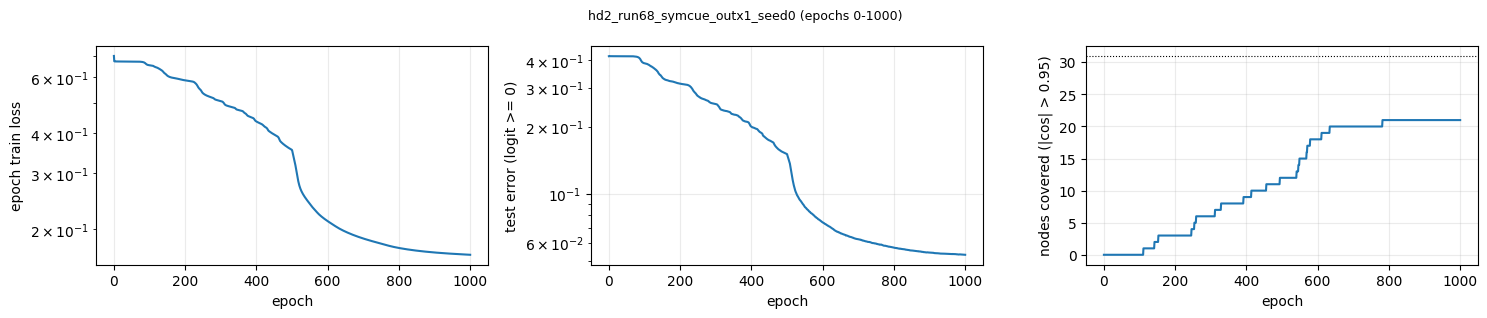

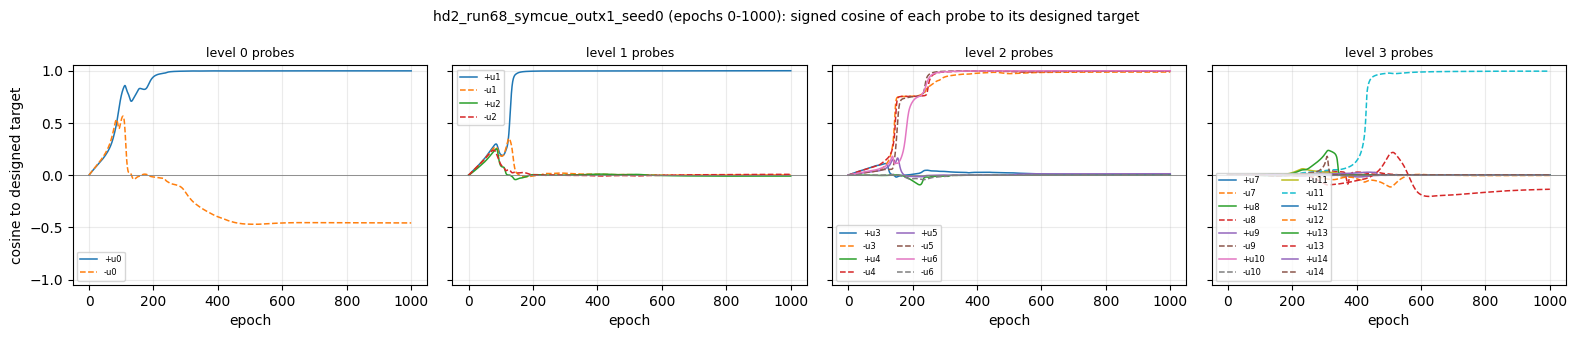

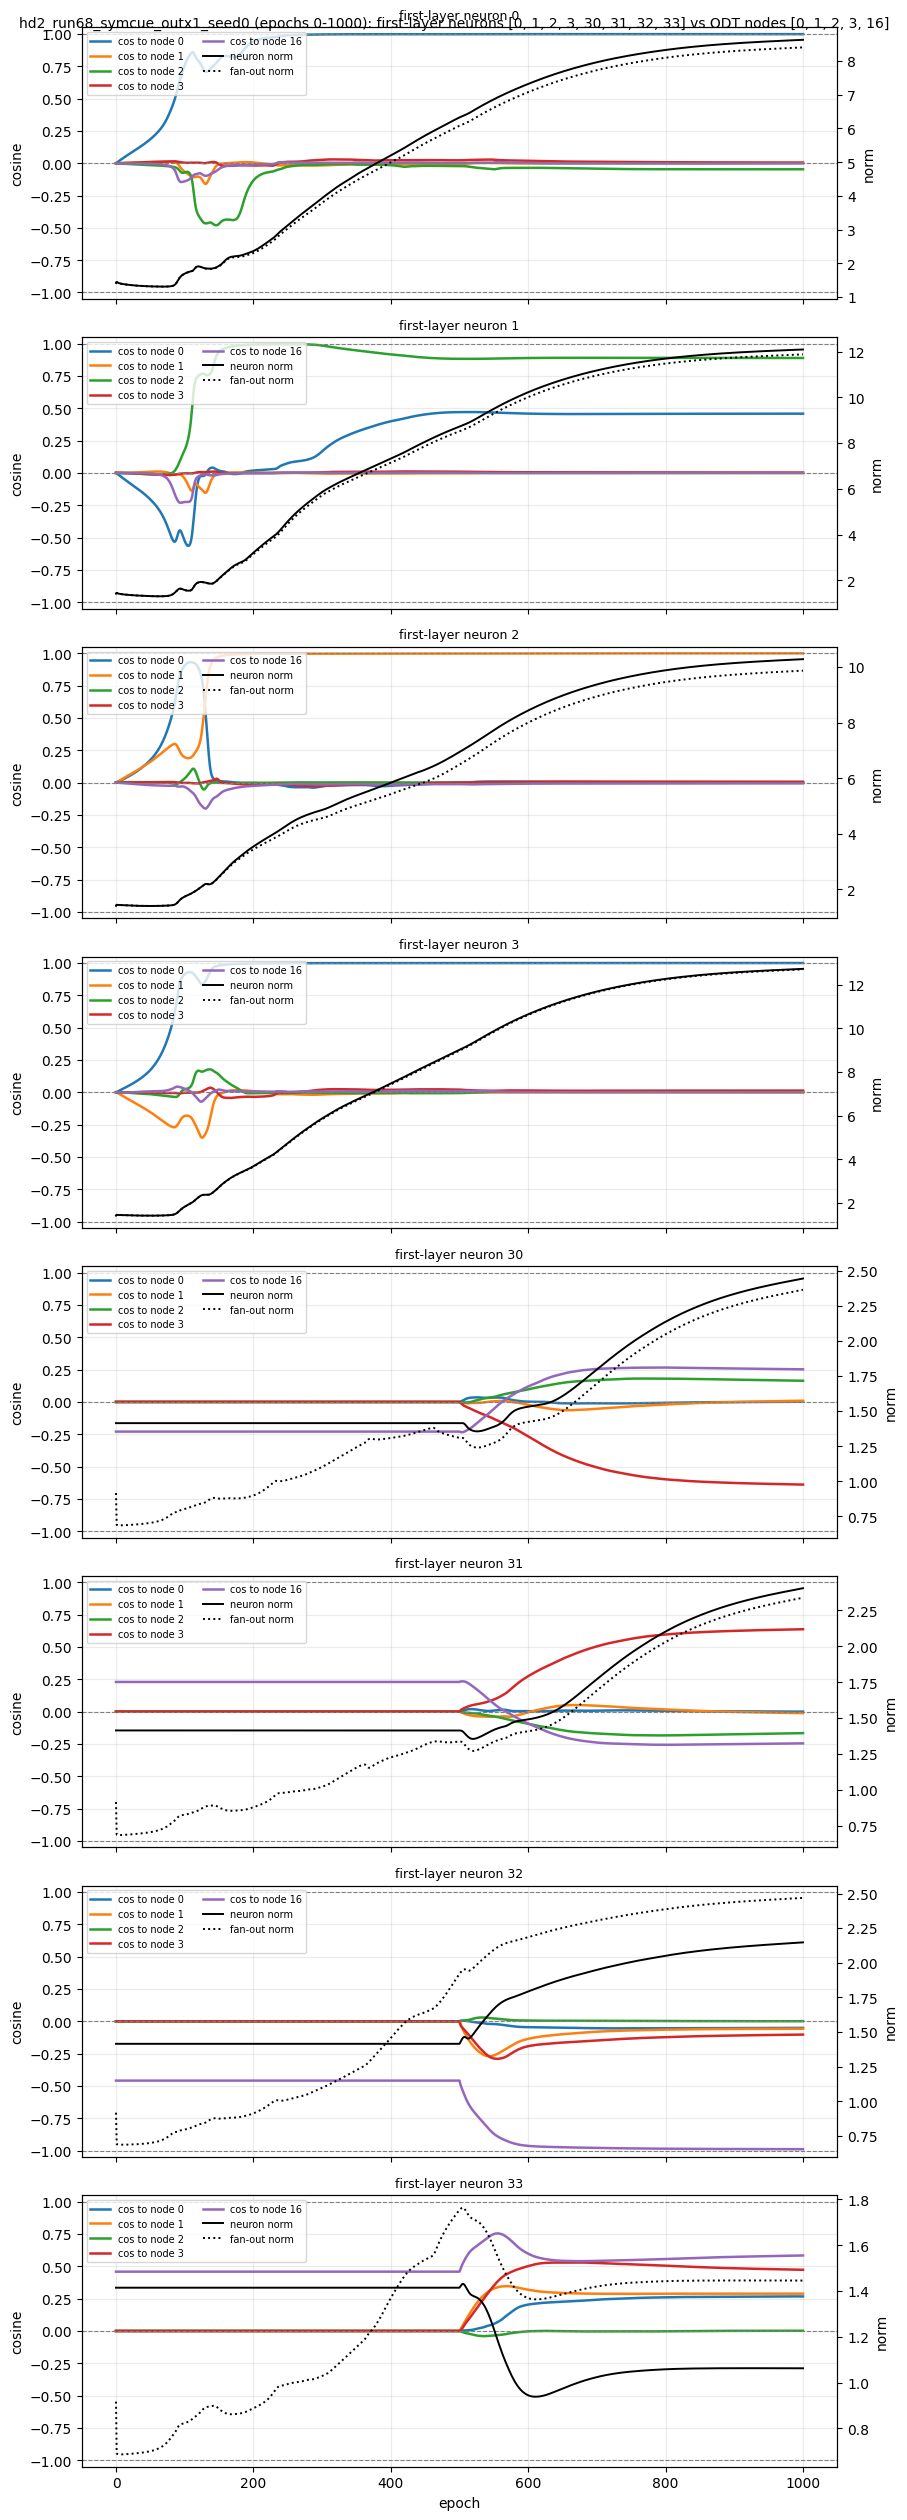

In [3]:
NEURON_IDS = [0, 1, 2, 3, 30, 31, 32, 33]
series68 = trajectory_plots(run68, NEURON_IDS, node_ids=None, end_epoch=int(run68["epochs"][-1]))

Visible edges: 2040 / 3780
First-layer aligned nodes: 0 / 62


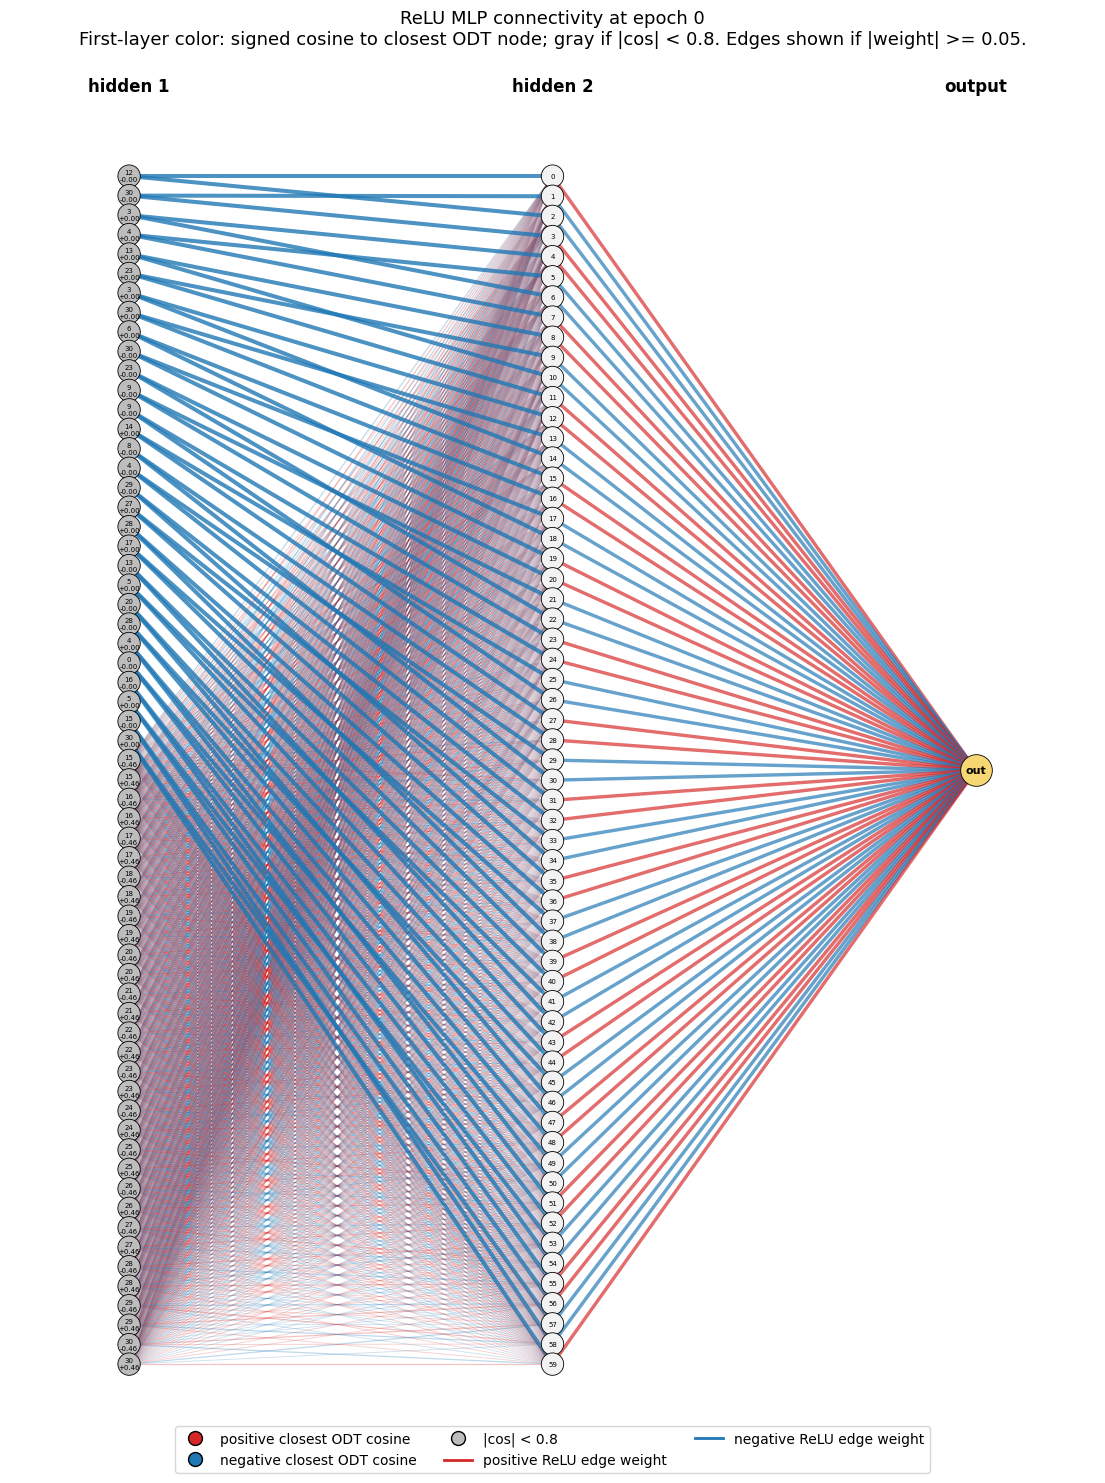

,row,group,designed_target,closest_node,level,signed_cos,norm


In [5]:
GRAPH_EPOCH = 0
table68 = network_view(run68, GRAPH_EPOCH, align_threshold=0.8, edge_threshold=0.05)

In [ ]:
# Cross-run cell: uses runs 60 and 68 (loads run 60 if needed). Loss, logit and readout over the first epochs, capture epochs, and the cue blocks' coherent part (pole-signed mean reading) and side contrast over time.
ensure_runs(60)
from layer_lenses.designed_init import cue_row_identity, probe_deviation_lineage, node_ancestors
def side_of(j, m):
    c = m
    while (c - 1) // 2 != j: c = (c - 1) // 2
    return 1 if c == 2 * j + 2 else -1
_rows = []
for n in [60, 68]:
    r = globals()[f"run{n}"]; W = r["W"]["hidden_layers.0.weight"]; W2 = r["W"]["hidden_layers.1.weight"]; Wo = r["W"]["output_layer.weight"]; cr = globals()[f"sr{n}"]["design"]["cue_rows"]; cid = cue_row_identity(W[0].astype(np.float64), tree, cr); inv = {v: k for k, v in cid.items()}; unode = np.array(globals()[f"sr{n}"]["design"]["unit_node"])
    C = W[-1] / np.linalg.norm(W[-1], axis=1, keepdims=True) @ tree.w_list.T; lin = probe_deviation_lineage(W[-1], tree); s = r["summary"]; first = {}
    for l in range(4):
        ps = [p for p in range(30) if NODE_LEVEL[HIERARCHY_TARGETS[p][0]] == l]; first[l] = None
        for i, e in enumerate(r["epochs"]):
            Ci = W[i] / np.linalg.norm(W[i], axis=1, keepdims=True) @ tree.w_list.T
            if all(abs(Ci[p]).argmax() == HIERARCHY_TARGETS[p][0] and abs(Ci[p]).max() > 0.95 for p in ps): first[l] = int(e); break
    def block_stats(i):
        coh, con = [], []
        for u in range(60):
            j = int(unode[u]); pr = [p for p in range(30) if W2[0][u, p] != 0][0]; open_side = -HIERARCHY_TARGETS[pr][1]; sg = np.sign(Wo[0][0, u]) if Wo[0][0, u] != 0 else 1
            c = {m: sum(W2[i][u, cid[(m, q)]] * q for q in (1, -1)) * sg for m in range(15, 31)}          # pole-signed reading per leaf, in units of the init readout sign
            coh.append(np.mean(list(c.values()))); con.append(np.mean([c[m] * (1 if side_of(j, m) == open_side else -1) for m in range(15, 31) if j in node_ancestors(m)]))
        return float(np.mean(coh)), float(np.mean(con))
    bs = {e: block_stats(list(r["epochs"]).index(e)) for e in (0, 5, 20, 100, 500, int(r["epochs"][-1]))}
    _rows.append({"run": n, "final loss": round(float(s.final_epoch_loss), 4), "loss end phase 1": round(float(r["losses"][499]), 4), "test error": round(float(s.test_error_end), 4), "nodes": int(s.nodes_covered_end),
                  "probes on own node": sum(1 for p in range(30) if abs(C[p]).argmax() == HIERARCHY_TARGETS[p][0] and abs(C[p]).max() > 0.95), "deviated": int(lin.deviated.sum()), "cues own": sum(1 for rr in cr if abs(C[rr]).argmax() == inv[rr][0] and abs(C[rr]).max() > 0.95),
                  "first epoch all probes of level 0/1/2/3 captured": first, "logit rms at 0 / 1 / 5 / 20 / 100": " / ".join(f"{np.sqrt(np.mean(logits_at(r, e) ** 2)):.2f}" for e in (0, 1, 5, 20, 100)), "|w_out| mean at 0 / 20 / 500 / end": " / ".join(f"{np.abs(Wo[list(r['epochs']).index(e)]).mean():.2f}" for e in (0, 20, 500, int(r["epochs"][-1]))),
                  "blocks: coherent reading (mean over leaves) at 0 / 5 / 20 / 100 / 500 / end": " / ".join(f"{bs[e][0]:+.3f}" for e in bs), "blocks: side contrast under the node at the same epochs": " / ".join(f"{bs[e][1]:+.3f}" for e in bs)})
print(pd.DataFrame(_rows).T.to_string())
plt.figure(figsize=(9, 3)); [plt.plot(globals()[f"run{n}"]["losses"], lw=0.7, label=f"run {n}") for n in [60, 68]]; plt.axvline(500, color="k", lw=0.5, ls="--"); plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("epoch loss"); plt.legend(); plt.show()

## 24. Run 69: run 68 with the doubling flipped (0.1 on the open side, 0.2 elsewhere)

| setting | value |
|---|---|
| init | run 68's with the two cue weights exchanged: every cue-to-unit weight = sign(readout) x pole x a with a = 0.1 for the leaves under the unit's node on its open side and 0.2 for every other cue (unit 0's row: -0.1, +0.1 alternating on the first 16 cues, -0.2, +0.2 on the next 16). Readouts +-0.816 |
| protocol | run 68's: plain SGD lr 0.1 -> 0.005 cosine over 1000 epochs, output rate x1, 10M points, cues frozen 0-500, free 500-1000 |
| storage | `results/designed_init/hd2_run69_symcue_flipped/replay/` |
| script | `run_hd2_phased.py --two-layer --momentum 0 --lr 0.1 --phases 500 500 --symmetric-cue-blocks 0.1 0.2` |

**Question.** The side contrast of the blocks changes sign relative to run 68 (the vetoed side reads more than the open side), so the lens predicts the first-order push on each probe to point at the opposite pole of its node. Does the probe go to the opposite pole, as the pole rule of runs 24-25 would say, or does the coherent reading dominate as in run 68?

**Findings.** Loss 0.221 (end of phase 1: 0.499; run 68: 0.355 / 0.167), test error 7.9% (5.3%), 17 nodes (21), **no probe on its own node at either pole**, 24 deviated (10 to ancestors, 10 unrelated, 4 to descendants), 6 cues on their node.
- **The pole rule does not apply: the probes do not go to the opposite pole, they do not go to their node at all.** The root probes' cosine with u_0 is 0.00 through epoch 100 (run 68: 0.76 and -0.53 at epoch 100, probe 0 on +u_0 by then) and -0.01 / -0.26 at epoch 500; they end on level-2 nodes 5 and 8. The root is captured instead by four level-3 probes climbing to it (16, 19, 22, 24), and nodes 1-3 by other climbers. The flipped contrast (-0.1 per leaf under the node, the same size as run 68's +0.1) is as far below the noise as run 68's was, and its sign only removes the weak directed push that run 68 still had at the root and level 1.
- **A larger coherent logit, a longer plateau.** With 0.2 on 24-30 of the 32 cues the initial logit rms is 9.0 (run 68: 5.1); it is shrunk to 0.42 in one epoch (readouts 0.82 -> 0.46 by epoch 20, the coherent reading of the blocks 0.37 -> 0.23 -> 0.21), and the loss then sits at 0.673 until epoch 200 (run 68: 50), the readouts reaching only 1.4 at epoch 500 and 2.9 at the end (run 68: 2.6 / 3.5). The side contrast stays negative throughout (-0.10 -> -0.064): gradient descent neither flips it nor builds the design's.
- **Reading.** Runs 68 and 69 together: with every cue path majority-aligned, the block's side asymmetry is a small correction on a large coherent reading, and the sign of that correction decides only whether the root and level-1 probes get a weak nudge toward their designed pole (run 68) or none (run 69); from level 2 down the push is noise in both, and the hierarchy is assembled by the lineage mechanism (probes climbing to ancestors) and random captures. The design's zero-coherence, full-contrast blocks are not a cosmetic choice: they are what makes the probe push dominate at every level.


In [ ]:
sr69, run69 = load_replay_run("hd2_run69_symcue_flipped", [62, 60])          # ~20 s
summary69 = findings_table(run69)

In [ ]:
NEURON_IDS = [0, 1, 2, 3, 30, 31, 32, 33]
series69 = trajectory_plots(run69, NEURON_IDS, node_ids=None, end_epoch=int(run69["epochs"][-1]))

In [ ]:
GRAPH_EPOCH = 1000
table69 = network_view(run69, GRAPH_EPOCH, align_threshold=0.8, edge_threshold=0.05)

In [ ]:
# Cross-run cell: uses runs 60, 68 and 69 (loads the missing ones). End state, capture, poles reached by the probes, block balance over time.
ensure_runs(60, 68)
from layer_lenses.designed_init import cue_row_identity, probe_deviation_lineage, node_ancestors
def side_of(j, m):
    c = m
    while (c - 1) // 2 != j: c = (c - 1) // 2
    return 1 if c == 2 * j + 2 else -1
_rows = []
for n in [60, 68, 69]:
    r = globals()[f"run{n}"]; W = r["W"]["hidden_layers.0.weight"]; W2 = r["W"]["hidden_layers.1.weight"]; Wo = r["W"]["output_layer.weight"]; cr = globals()[f"sr{n}"]["design"]["cue_rows"]; cid = cue_row_identity(W[0].astype(np.float64), tree, cr); inv = {v: k for k, v in cid.items()}; unode = np.array(globals()[f"sr{n}"]["design"]["unit_node"])
    C = W[-1] / np.linalg.norm(W[-1], axis=1, keepdims=True) @ tree.w_list.T; lin = probe_deviation_lineage(W[-1], tree); s = r["summary"]
    same = sum(1 for p in range(30) if abs(C[p]).argmax() == HIERARCHY_TARGETS[p][0] and abs(C[p]).max() > 0.95 and np.sign(C[p][HIERARCHY_TARGETS[p][0]]) == HIERARCHY_TARGETS[p][1]); opp = sum(1 for p in range(30) if abs(C[p]).argmax() == HIERARCHY_TARGETS[p][0] and abs(C[p]).max() > 0.95 and np.sign(C[p][HIERARCHY_TARGETS[p][0]]) == -HIERARCHY_TARGETS[p][1])
    def block_stats(i):
        coh, con = [], []
        for u in range(60):
            j = int(unode[u]); pr = [p for p in range(30) if W2[0][u, p] != 0][0]; open_side = -HIERARCHY_TARGETS[pr][1]; sg = np.sign(Wo[0][0, u])
            c = {m: sum(W2[i][u, cid[(m, q)]] * q for q in (1, -1)) * sg for m in range(15, 31)}; coh.append(np.mean(list(c.values()))); con.append(np.mean([c[m] * (1 if side_of(j, m) == open_side else -1) for m in range(15, 31) if j in node_ancestors(m)]))
        return float(np.mean(coh)), float(np.mean(con))
    bs = {e: block_stats(list(r["epochs"]).index(e)) for e in (0, 1, 20, 100, 500, int(r["epochs"][-1]))}
    _rows.append({"run": n, "final loss": round(float(s.final_epoch_loss), 4), "loss end phase 1": round(float(r["losses"][499]), 4), "test error": round(float(s.test_error_end), 4), "nodes": int(s.nodes_covered_end), "probes on own node: designed pole / opposite pole": f"{same} / {opp}", "deviated": int(lin.deviated.sum()), "relations": lin[lin.deviated].relation.value_counts().to_dict(),
                  "cues own": sum(1 for rr in cr if abs(C[rr]).argmax() == inv[rr][0] and abs(C[rr]).max() > 0.95), "blocks: coherent reading at 0 / 1 / 20 / 100 / 500 / end": " / ".join(f"{bs[e][0]:+.3f}" for e in bs), "blocks: side contrast (open minus vetoed) at the same epochs": " / ".join(f"{bs[e][1]:+.3f}" for e in bs)})
print(pd.DataFrame(_rows).T.to_string())
plt.figure(figsize=(9, 3)); [plt.plot(globals()[f"run{n}"]["losses"], lw=0.7, label=f"run {n}") for n in [60, 68, 69]]; plt.axvline(500, color="k", lw=0.5, ls="--"); plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("epoch loss"); plt.legend(); plt.show()